# Global Electronics Retail Sales & Profitability Analysis

## 1. Data Loading and Validation

This notebook validates and prepares the Global Electronics Retailers dataset
before business analysis.

The dataset consists of five related tables:

- Sales
- Products
- Customers
- Stores
- Exchange Rates

The initial validation stage focuses on:

- Dataset dimensions
- Column names and data types
- Missing values
- Duplicate records
- Primary key uniqueness
- Foreign key integrity
- Date ranges
- Financial metric validation

No cleaning decisions are made before completing data validation.

In [1]:
import pandas as pd
import numpy as np

In [2]:
sales = pd.read_csv("data/Sales.csv")
products = pd.read_csv("data/Products.csv")

customers = pd.read_csv(
    "data/Customers.csv",
    encoding="cp1252"
)

stores = pd.read_csv("data/Stores.csv")
exchange_rates = pd.read_csv("data/Exchange_Rates.csv")

In [3]:
customers.head()

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,7/3/1939
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,9/27/1979
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,5/26/1947
3,786,Male,Jai Poltpalingada,MIDDLE RIVER,SA,South Australia,5223,Australia,Australia,9/17/1957
4,1042,Male,Aidan Pankhurst,TAWONGA SOUTH,VIC,Victoria,3698,Australia,Australia,11/19/1965


In [4]:
customers.shape

(15266, 10)

In [5]:
datasets = {
    "Sales": sales,
    "Products": products,
    "Customers": customers,
    "Stores": stores,
    "Exchange Rates": exchange_rates
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Sales: 62,884 rows, 9 columns
Products: 2,517 rows, 10 columns
Customers: 15,266 rows, 10 columns
Stores: 67 rows, 5 columns
Exchange Rates: 11,215 rows, 3 columns


In [6]:
for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(name)
    print(df.columns.tolist())


Sales
['Order Number', 'Line Item', 'Order Date', 'Delivery Date', 'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code']

Products
['ProductKey', 'Product Name', 'Brand', 'Color', 'Unit Cost USD', 'Unit Price USD', 'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category']

Customers
['CustomerKey', 'Gender', 'Name', 'City', 'State Code', 'State', 'Zip Code', 'Country', 'Continent', 'Birthday']

Stores
['StoreKey', 'Country', 'State', 'Square Meters', 'Open Date']

Exchange Rates
['Date', 'Currency', 'Exchange']


## 2. Data Quality Validation

Before cleaning or transforming the data, each table is validated for:

- Missing values
- Duplicate records
- Primary key uniqueness
- Sales transaction uniqueness
- Foreign key integrity
- Date consistency
- Currency and exchange-rate coverage

No records are removed or modified during this stage.

In [7]:
for name, df in datasets.items():
    missing = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing %": (df.isna().sum() / len(df) * 100).round(2)
    })

    missing = missing[missing["Missing Count"] > 0]

    print(f"\n{name}")
    display(missing)


Sales


,Missing Count,Missing %
Delivery Date,49719,79.06



Products


,Missing Count,Missing %



Customers


,Missing Count,Missing %
State Code,10,0.07



Stores


,Missing Count,Missing %
Square Meters,1,1.49



Exchange Rates


,Missing Count,Missing %


In [8]:
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum():,} exact duplicate rows"
    )

Sales: 0 exact duplicate rows
Products: 0 exact duplicate rows
Customers: 0 exact duplicate rows
Stores: 0 exact duplicate rows
Exchange Rates: 0 exact duplicate rows


In [9]:
key_checks = {
    "Products": (products, "ProductKey"),
    "Customers": (customers, "CustomerKey"),
    "Stores": (stores, "StoreKey")
}

for name, (df, key) in key_checks.items():
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Unique keys:", df[key].nunique())
    print("Duplicate keys:", df[key].duplicated().sum())
    print("Missing keys:", df[key].isna().sum())


Products
Rows: 2517
Unique keys: 2517
Duplicate keys: 0
Missing keys: 0

Customers
Rows: 15266
Unique keys: 15266
Duplicate keys: 0
Missing keys: 0

Stores
Rows: 67
Unique keys: 67
Duplicate keys: 0
Missing keys: 0


In [10]:
sales_key_duplicates = sales.duplicated(
    subset=["Order Number", "Line Item"]
).sum()

print(
    "Duplicate Order Number + Line Item:",
    sales_key_duplicates
)

Duplicate Order Number + Line Item: 0


In [11]:
print("Sales rows:", f"{len(sales):,}")
print(
    "Unique orders:",
    f"{sales['Order Number'].nunique():,}"
)

Sales rows: 62,884
Unique orders: 26,326


In [12]:
missing_customer_keys = set(sales["CustomerKey"]) - set(customers["CustomerKey"])

print("Unmatched CustomerKeys:", len(missing_customer_keys))
print(sorted(missing_customer_keys)[:20])

Unmatched CustomerKeys: 0
[]


In [13]:
missing_product_keys = set(sales["ProductKey"]) - set(products["ProductKey"])

print("Unmatched ProductKeys:", len(missing_product_keys))
print(sorted(missing_product_keys)[:20])

Unmatched ProductKeys: 0
[]


In [14]:
missing_store_keys = set(sales["StoreKey"]) - set(stores["StoreKey"])

print("Unmatched StoreKeys:", len(missing_store_keys))
print(sorted(missing_store_keys)[:20])

Unmatched StoreKeys: 0
[]


In [15]:
exchange_duplicate_keys = exchange_rates.duplicated(
    subset=["Date", "Currency"]
).sum()

print(
    "Duplicate Date + Currency combinations:",
    exchange_duplicate_keys
)

Duplicate Date + Currency combinations: 0


In [16]:
print("Sales currencies:")
print(sorted(sales["Currency Code"].unique()))

print("\nExchange-rate currencies:")
print(sorted(exchange_rates["Currency"].unique()))

Sales currencies:
['AUD', 'CAD', 'EUR', 'GBP', 'USD']

Exchange-rate currencies:
['AUD', 'CAD', 'EUR', 'GBP', 'USD']


In [17]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.dtypes)


Sales
Order Number     int64
Line Item        int64
Order Date         str
Delivery Date      str
CustomerKey      int64
StoreKey         int64
ProductKey       int64
Quantity         int64
Currency Code      str
dtype: object

Products
ProductKey        int64
Product Name        str
Brand               str
Color               str
Unit Cost USD       str
Unit Price USD      str
SubcategoryKey    int64
Subcategory         str
CategoryKey       int64
Category            str
dtype: object

Customers
CustomerKey    int64
Gender           str
Name             str
City             str
State Code       str
State            str
Zip Code         str
Country          str
Continent        str
Birthday         str
dtype: object

Stores
StoreKey           int64
Country              str
State                str
Square Meters    float64
Open Date            str
dtype: object

Exchange Rates
Date            str
Currency        str
Exchange    float64
dtype: object


In [18]:
stores[stores["Square Meters"].isna()]

,StoreKey,Country,State,Square Meters,Open Date
66,0,Online,Online,NaN,1/1/2010


In [19]:
sales.groupby(
    sales["Delivery Date"].isna()
)["StoreKey"].nunique()

Delivery Date
False     1
True     57
Name: StoreKey, dtype: int64

In [20]:
delivery_by_store = (
    sales
    .assign(Delivery_Missing=sales["Delivery Date"].isna())
    .groupby(["StoreKey", "Delivery_Missing"])
    .size()
    .unstack(fill_value=0)
)

delivery_by_store

Delivery_Missing,False,True
StoreKey,,
0,13165,0
1,0,292
2,0,18
4,0,431
5,0,892
6,0,615
8,0,1360
9,0,1577
10,0,1269


In [21]:
sales[sales["Delivery Date"].notna()]["StoreKey"].value_counts().head(20)

StoreKey
0    13165
Name: count, dtype: int64

In [22]:
products[
    ["Unit Cost USD", "Unit Price USD"]
].head(20)

,Unit Cost USD,Unit Price USD
0,$6.62,$12.99
1,$6.62,$12.99
2,$7.40,$14.52
3,$11.00,$21.57
4,$11.00,$21.57
5,$11.00,$21.57
6,$11.00,$21.57
7,$30.58,$59.99
8,$30.58,$59.99
9,$30.58,$59.99


In [23]:
products[
    ["Unit Cost USD", "Unit Price USD"]
].sample(20, random_state=42)

,Unit Cost USD,Unit Price USD
2195,$40.76,$79.95
410,$321.44,$699.00
1389,$17.93,$38.99
888,$25.49,$50.00
1771,$17.33,$34.00
56,$79.53,$156.00
44,$106.69,$232.00
1106,$164.63,$358.00
368,$321.44,$699.00
1738,$14.28,$28.00


In [24]:
print("Sales Order Date:")
print(sales["Order Date"].head(10).tolist())

print("\nSales Delivery Date:")
print(sales["Delivery Date"].dropna().head(10).tolist())

print("\nCustomer Birthday:")
print(customers["Birthday"].head(10).tolist())

print("\nStore Open Date:")
print(stores["Open Date"].head(10).tolist())

print("\nExchange Rate Date:")
print(exchange_rates["Date"].head(10).tolist())

Sales Order Date:
['1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016', '1/1/2016']

Sales Delivery Date:
['1/13/2016', '1/13/2016', '1/12/2016', '1/12/2016', '1/12/2016', '1/8/2016', '1/6/2016', '1/6/2016', '1/10/2016', '1/10/2016']

Customer Birthday:
['7/3/1939', '9/27/1979', '5/26/1947', '9/17/1957', '11/19/1965', '1/20/1954', '11/22/1969', '3/12/1950', '12/21/1965', '7/25/1975']

Store Open Date:
['1/1/2008', '1/12/2008', '1/7/2012', '1/1/2010', '12/9/2015', '1/1/2010', '5/7/2007', '7/2/2014', '3/4/2005', '4/4/2015']

Exchange Rate Date:
['1/1/2015', '1/1/2015', '1/1/2015', '1/1/2015', '1/1/2015', '1/2/2015', '1/2/2015', '1/2/2015', '1/2/2015', '1/2/2015']


## 3. Data Cleaning

The validation stage showed that the dataset is structurally consistent.

Key findings before cleaning:

- No exact duplicate records were found.
- Primary and foreign key relationships are valid.
- Missing `Delivery Date` values represent in-store purchases and are therefore expected.
- The missing `Square Meters` value belongs to the online store and is not considered a data-quality issue.
- Product cost and price fields are stored as text because they contain currency symbols.
- Date fields use the MM/DD/YYYY format.

The original DataFrames are preserved, and cleaning is performed on copies.

In [25]:
sales_clean = sales.copy()
products_clean = products.copy()
customers_clean = customers.copy()
stores_clean = stores.copy()
exchange_rates_clean = exchange_rates.copy()

In [26]:
price_columns = ["Unit Cost USD", "Unit Price USD"]

for col in price_columns:
    products_clean[col] = (
        products_clean[col]
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

In [27]:
products_clean[price_columns].dtypes

Unit Cost USD     float64
Unit Price USD    float64
dtype: object

In [28]:
products_clean[price_columns].describe()

,Unit Cost USD,Unit Price USD
count,2517.000000,2517.000000
mean,147.655562,356.830131
std,184.373683,494.054962
min,0.480000,0.950000
25%,32.250000,69.000000
50%,86.670000,199.990000
75%,183.950000,410.000000
max,1060.220000,3199.990000


In [29]:
print(
    "Products where cost exceeds price:",
    (products_clean["Unit Cost USD"] > products_clean["Unit Price USD"]).sum()
)

Products where cost exceeds price: 0


In [30]:
sales_clean["Order Date"] = pd.to_datetime(
    sales_clean["Order Date"],
    format="%m/%d/%Y"
)

sales_clean["Delivery Date"] = pd.to_datetime(
    sales_clean["Delivery Date"],
    format="%m/%d/%Y"
)

customers_clean["Birthday"] = pd.to_datetime(
    customers_clean["Birthday"],
    format="%m/%d/%Y"
)

stores_clean["Open Date"] = pd.to_datetime(
    stores_clean["Open Date"],
    format="%m/%d/%Y"
)

exchange_rates_clean["Date"] = pd.to_datetime(
    exchange_rates_clean["Date"],
    format="%m/%d/%Y"
)

In [31]:
print(sales_clean[["Order Date", "Delivery Date"]].dtypes)
print(customers_clean["Birthday"].dtype)
print(stores_clean["Open Date"].dtype)
print(exchange_rates_clean["Date"].dtype)

Order Date       datetime64[us]
Delivery Date    datetime64[us]
dtype: object
datetime64[us]
datetime64[us]
datetime64[us]


In [32]:
customers_clean.loc[
    customers_clean["State Code"].isna(),
    ["CustomerKey", "City", "State", "Country", "Zip Code"]
]

,CustomerKey,City,State,Country,Zip Code
5304,729681,Polvica,Napoli,Italy,80035
5316,732289,Varcaturo,Napoli,Italy,80014
5372,742042,Casaferro,Napoli,Italy,80034
5377,742886,Terzigno,Napoli,Italy,80040
5378,743343,Pomigliano D'Arco,Napoli,Italy,80038
5485,759705,Casilli,Napoli,Italy,80047
5525,765589,Pompei Scavi,Napoli,Italy,80045
5531,766410,Licola,Napoli,Italy,80078
5631,781667,Napoli,Napoli,Italy,80134
5695,789177,Mariglianella,Napoli,Italy,80030


In [33]:
customers_clean.loc[
    customers_clean["Country"].eq("Italy"),
    ["State", "State Code"]
].drop_duplicates().sort_values(["State", "State Code"])

,State,State Code
5122,Agrigento,AG
5247,Alessandria,AL
5151,Ancona,AN
5417,Aosta,AO
5388,Arezzo,AR
...,...,...
5231,Vercelli,VC
5206,Verona,VR
5146,Vibo Valentia,VV
5118,Vicenza,VI


In [34]:
customers_clean.loc[
    customers_clean["State"].eq("Napoli"),
    ["State", "State Code"]
].drop_duplicates()

,State,State Code
5304,Napoli,NaN


## 4. Financial Metric Validation

Sales transactions are joined with product pricing data to calculate revenue,
cost, profit, and profit margin.

The calculations are derived from the original product price and cost fields
rather than relying on pre-calculated financial metrics.

In [35]:
sales_analysis = sales_clean.merge(
    products_clean[
        [
            "ProductKey",
            "Product Name",
            "Brand",
            "Subcategory",
            "Category",
            "Unit Cost USD",
            "Unit Price USD"
        ]
    ],
    on="ProductKey",
    how="left",
    validate="many_to_one"
)

In [36]:
print("Original sales rows:", len(sales_clean))
print("Merged sales rows:", len(sales_analysis))

Original sales rows: 62884
Merged sales rows: 62884


In [37]:
sales_analysis[
    ["Unit Cost USD", "Unit Price USD"]
].isna().sum()

Unit Cost USD     0
Unit Price USD    0
dtype: int64

In [38]:
sales_analysis["Revenue USD"] = (
    sales_analysis["Quantity"]
    * sales_analysis["Unit Price USD"]
)

sales_analysis["Cost USD"] = (
    sales_analysis["Quantity"]
    * sales_analysis["Unit Cost USD"]
)

sales_analysis["Profit USD"] = (
    sales_analysis["Revenue USD"]
    - sales_analysis["Cost USD"]
)

sales_analysis["Profit Margin %"] = (
    sales_analysis["Profit USD"]
    / sales_analysis["Revenue USD"]
    * 100
)

In [39]:
sales_analysis[
    [
        "Quantity",
        "Unit Cost USD",
        "Unit Price USD",
        "Revenue USD",
        "Cost USD",
        "Profit USD",
        "Profit Margin %"
    ]
].describe()

,Quantity,Unit Cost USD,Unit Price USD,Revenue USD,Cost USD,Profit USD,Profit Margin %
count,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000
mean,3.144790,116.253013,280.569848,886.640156,367.228408,519.411748,54.904210
std,2.256371,140.033327,382.827515,1648.480286,614.548869,1052.204029,6.412808
min,1.000000,0.480000,0.950000,0.950000,0.480000,0.470000,48.945148
25%,1.000000,22.050000,47.950000,115.000000,52.880000,61.560000,49.021135
50%,2.000000,79.530000,181.000000,360.000000,164.160000,194.440000,54.013193
75%,4.000000,138.420000,300.000000,969.000000,423.080000,540.140000,54.018445
max,10.000000,1060.220000,3199.990000,31999.900000,10602.200000,21397.700000,66.885103


In [40]:
print(
    "Zero or negative quantities:",
    (sales_analysis["Quantity"] <= 0).sum()
)

print(
    "Zero or negative revenue:",
    (sales_analysis["Revenue USD"] <= 0).sum()
)

print(
    "Negative profit rows:",
    (sales_analysis["Profit USD"] < 0).sum()
)

print(
    "Profit margin above 100%:",
    (sales_analysis["Profit Margin %"] > 100).sum()
)

print(
    "Missing calculated values:",
    sales_analysis[
        [
            "Revenue USD",
            "Cost USD",
            "Profit USD",
            "Profit Margin %"
        ]
    ].isna().sum().sum()
)

Zero or negative quantities: 0
Zero or negative revenue: 0
Negative profit rows: 0
Profit margin above 100%: 0
Missing calculated values: 0


In [41]:
print(
    "Total Revenue USD:",
    f"${sales_analysis['Revenue USD'].sum():,.2f}"
)

print(
    "Total Cost USD:",
    f"${sales_analysis['Cost USD'].sum():,.2f}"
)

print(
    "Total Profit USD:",
    f"${sales_analysis['Profit USD'].sum():,.2f}"
)

overall_margin = (
    sales_analysis["Profit USD"].sum()
    / sales_analysis["Revenue USD"].sum()
    * 100
)

print(
    "Overall Profit Margin:",
    f"{overall_margin:.2f}%"
)

Total Revenue USD: $55,755,479.59
Total Cost USD: $23,092,791.21
Total Profit USD: $32,662,688.38
Overall Profit Margin: 58.58%


In [42]:
customers_check = pd.read_csv(
    "data/Customers.csv",
    encoding="cp1252",
    keep_default_na=False
)

customers_check.loc[
    customers_check["State"].eq("Napoli"),
    ["State", "State Code"]
].drop_duplicates()

,State,State Code
5304,Napoli,NA


In [43]:
print(
    "Sales period:",
    sales_clean["Order Date"].min(),
    "to",
    sales_clean["Order Date"].max()
)

print(
    "Delivery period:",
    sales_clean["Delivery Date"].min(),
    "to",
    sales_clean["Delivery Date"].max()
)

print(
    "Exchange-rate period:",
    exchange_rates_clean["Date"].min(),
    "to",
    exchange_rates_clean["Date"].max()
)

print(
    "Store opening period:",
    stores_clean["Open Date"].min(),
    "to",
    stores_clean["Open Date"].max()
)

print(
    "Customer birthday period:",
    customers_clean["Birthday"].min(),
    "to",
    customers_clean["Birthday"].max()
)

Sales period: 2016-01-01 00:00:00 to 2021-02-20 00:00:00
Delivery period: 2016-01-06 00:00:00 to 2021-02-27 00:00:00
Exchange-rate period: 2015-01-01 00:00:00 to 2021-02-20 00:00:00
Store opening period: 2005-03-04 00:00:00 to 2019-03-05 00:00:00
Customer birthday period: 1935-02-03 00:00:00 to 2002-02-18 00:00:00


In [44]:
print(
    "Online orders without delivery date:",
    sales_clean.loc[
        sales_clean["StoreKey"].eq(0),
        "Delivery Date"
    ].isna().sum()
)

print(
    "Physical-store transactions with delivery date:",
    sales_clean.loc[
        sales_clean["StoreKey"].ne(0),
        "Delivery Date"
    ].notna().sum()
)

print(
    "Delivery before order:",
    (
        sales_clean["Delivery Date"]
        < sales_clean["Order Date"]
    ).sum()
)

Online orders without delivery date: 0
Physical-store transactions with delivery date: 0
Delivery before order: 0


In [45]:
store_validation = sales_clean.merge(
    stores_clean[
        ["StoreKey", "Open Date"]
    ],
    on="StoreKey",
    how="left",
    validate="many_to_one"
)

sales_before_opening = store_validation[
    (store_validation["StoreKey"] != 0)
    &
    (
        store_validation["Order Date"]
        < store_validation["Open Date"]
    )
]

print(
    "Sales before store opening:",
    len(sales_before_opening)
)

Sales before store opening: 0


In [46]:
fx_validation = sales_clean.merge(
    exchange_rates_clean,
    left_on=["Order Date", "Currency Code"],
    right_on=["Date", "Currency"],
    how="left",
    validate="many_to_one"
)

print(
    "Sales without matching exchange rate:",
    fx_validation["Exchange"].isna().sum()
)

print(
    "Zero or negative exchange rates:",
    (exchange_rates_clean["Exchange"] <= 0).sum()
)

Sales without matching exchange rate: 0
Zero or negative exchange rates: 0


In [47]:
exchange_rates_clean.groupby("Currency")["Exchange"].agg(
    ["count", "min", "max", "mean"]
)

,count,min,max,mean
Currency,,,,
AUD,2243,1.2080,1.7253,1.367305
CAD,2243,1.1583,1.4637,1.310171
EUR,2243,0.8004,0.9649,0.883785
GBP,2243,0.6285,0.8622,0.747151
USD,2243,1.0000,1.0000,1.000000


In [48]:
customers = pd.read_csv(
    "data/Customers.csv",
    encoding="cp1252",
    keep_default_na=False,
    na_values=[""]
)

In [49]:
customers_clean = customers.copy()

customers_clean["Birthday"] = pd.to_datetime(
    customers_clean["Birthday"],
    format="%m/%d/%Y"
)

In [50]:
customers_clean.isna().sum()

CustomerKey    0
Gender         0
Name           0
City           0
State Code     0
State          0
Zip Code       0
Country        0
Continent      0
Birthday       0
dtype: int64

### Validation Summary

The dataset passed the main structural and financial validation checks.

Key findings:

- No exact duplicate records were found.
- Product, customer, and store keys are unique.
- All sales records successfully match their related product, customer, and store records.
- Each sales transaction is uniquely identified by Order Number and Line Item.
- Missing Delivery Date values are expected for physical-store purchases; online transactions contain delivery dates.
- The missing Square Meters value belongs to the online store and is therefore expected.
- The apparent missing State Code values for Napoli were caused by pandas interpreting the literal value "NA" as a missing value. The CSV was reloaded while preserving "NA" as text.
- Product prices and costs were converted from currency-formatted strings to numeric values.
- Date fields were converted to datetime using the MM/DD/YYYY format.
- No sales occurred before a store's opening date.
- No delivery dates occur before their corresponding order dates.
- Every sales transaction has a matching exchange rate.
- No zero or negative quantities, revenue values, or profit values were found.
- The dataset covers sales from January 1, 2016 through February 20, 2021. Because 2021 is a partial year, year-over-year comparisons must treat it separately.

### Financial Validation Results

Financial metrics were derived directly from quantity, unit price, and unit cost:

- Total Revenue: $55.76M
- Total Cost: $23.09M
- Total Profit: $32.66M
- Overall Profit Margin: 58.58%

No negative profit transactions, invalid quantities, or missing calculated financial values were identified.

In [51]:
sales_analysis = sales_clean.copy()

# Add product information
sales_analysis = sales_analysis.merge(
    products_clean[
        [
            "ProductKey",
            "Product Name",
            "Brand",
            "Subcategory",
            "Category",
            "Unit Cost USD",
            "Unit Price USD"
        ]
    ],
    on="ProductKey",
    how="left",
    validate="many_to_one"
)

# Calculate financial metrics
sales_analysis["Revenue USD"] = (
    sales_analysis["Quantity"] * sales_analysis["Unit Price USD"]
)

sales_analysis["Cost USD"] = (
    sales_analysis["Quantity"] * sales_analysis["Unit Cost USD"]
)

sales_analysis["Profit USD"] = (
    sales_analysis["Revenue USD"] - sales_analysis["Cost USD"]
)

sales_analysis["Profit Margin %"] = (
    sales_analysis["Profit USD"]
    / sales_analysis["Revenue USD"]
    * 100
)

In [52]:
customers_for_analysis = customers_clean[
    [
        "CustomerKey",
        "Gender",
        "City",
        "State",
        "Country",
        "Continent",
        "Birthday"
    ]
].rename(
    columns={
        "City": "Customer City",
        "State": "Customer State",
        "Country": "Customer Country"
    }
)

sales_analysis = sales_analysis.merge(
    customers_for_analysis,
    on="CustomerKey",
    how="left",
    validate="many_to_one"
)

In [53]:
stores_for_analysis = stores_clean[
    [
        "StoreKey",
        "Country",
        "State",
        "Square Meters",
        "Open Date"
    ]
].rename(
    columns={
        "Country": "Store Country",
        "State": "Store State",
        "Open Date": "Store Open Date"
    }
)

sales_analysis = sales_analysis.merge(
    stores_for_analysis,
    on="StoreKey",
    how="left",
    validate="many_to_one"
)

In [54]:
print(sales_analysis.shape)
print(sales_analysis.columns.tolist())

(62884, 29)
['Order Number', 'Line Item', 'Order Date', 'Delivery Date', 'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code', 'Product Name', 'Brand', 'Subcategory', 'Category', 'Unit Cost USD', 'Unit Price USD', 'Revenue USD', 'Cost USD', 'Profit USD', 'Profit Margin %', 'Gender', 'Customer City', 'Customer State', 'Customer Country', 'Continent', 'Birthday', 'Store Country', 'Store State', 'Square Meters', 'Store Open Date']


In [55]:
sales_analysis["Year"] = sales_analysis["Order Date"].dt.year
sales_analysis["Month"] = sales_analysis["Order Date"].dt.month
sales_analysis["Month Name"] = sales_analysis["Order Date"].dt.month_name()
sales_analysis["Year-Month"] = sales_analysis["Order Date"].dt.to_period("M")

sales_analysis["Sales Channel"] = np.where(
    sales_analysis["StoreKey"] == 0,
    "Online",
    "Physical Store"
)

sales_analysis["Delivery Days"] = (
    sales_analysis["Delivery Date"]
    - sales_analysis["Order Date"]
).dt.days

In [56]:
sales_analysis["Customer Age"] = (
    sales_analysis["Order Date"].dt.year
    - sales_analysis["Birthday"].dt.year
    - (
        (
            sales_analysis["Order Date"].dt.month
            < sales_analysis["Birthday"].dt.month
        )
        |
        (
            (
                sales_analysis["Order Date"].dt.month
                == sales_analysis["Birthday"].dt.month
            )
            &
            (
                sales_analysis["Order Date"].dt.day
                < sales_analysis["Birthday"].dt.day
            )
        )
    ).astype(int)
)

In [57]:
sales_analysis[
    [
        "Order Date",
        "Year",
        "Month Name",
        "Sales Channel",
        "Delivery Days",
        "Birthday",
        "Customer Age"
    ]
].head(10)

,Order Date,Year,Month Name,Sales Channel,Delivery Days,Birthday,Customer Age
0,2016-01-01,2016,January,Physical Store,NaN,1971-03-23,44
1,2016-01-01,2016,January,Online,12.0,1995-11-20,20
2,2016-01-01,2016,January,Online,12.0,1995-11-20,20
3,2016-01-01,2016,January,Online,11.0,1962-08-24,53
4,2016-01-01,2016,January,Online,11.0,1962-08-24,53
5,2016-01-01,2016,January,Online,11.0,1962-08-24,53
6,2016-01-01,2016,January,Physical Store,NaN,1979-11-28,36
7,2016-01-01,2016,January,Physical Store,NaN,1979-11-28,36
8,2016-01-01,2016,January,Physical Store,NaN,1995-06-22,20
9,2016-01-01,2016,January,Physical Store,NaN,1944-10-30,71


In [58]:
sales_analysis[
    [
        "Revenue USD",
        "Cost USD",
        "Profit USD",
        "Profit Margin %",
        "Customer Age",
        "Delivery Days"
    ]
].describe()

,Revenue USD,Cost USD,Profit USD,Profit Margin %,Customer Age,Delivery Days
count,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000,13165.000000
mean,886.640156,367.228408,519.411748,54.904210,49.486388,4.529130
std,1648.480286,614.548869,1052.204029,6.412808,19.444818,2.121071
min,0.950000,0.480000,0.470000,48.945148,14.000000,1.000000
25%,115.000000,52.880000,61.560000,49.021135,33.000000,3.000000
50%,360.000000,164.160000,194.440000,54.013193,49.000000,4.000000
75%,969.000000,423.080000,540.140000,54.018445,66.000000,6.000000
max,31999.900000,10602.200000,21397.700000,66.885103,85.000000,17.000000


yearly_performance = (
    sales_analysis
    .groupby("Year")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

yearly_performance["Profit_Margin_%"] = (
    yearly_performance["Profit_USD"]
    / yearly_performance["Revenue_USD"]
    * 100
)

yearly_performance

In [59]:
yearly_performance = (
    sales_analysis
    .groupby("Year")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

yearly_performance["Profit_Margin_%"] = (
    yearly_performance["Profit_USD"]
    / yearly_performance["Revenue_USD"]
    * 100
)

yearly_performance

,Year,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%
0,2016,6946793.56,4107000.47,2865,21761,59.120808
1,2017,7421422.27,4337064.06,3280,24798,58.439796
2,2018,12788960.66,7464961.11,5965,44498,58.370350
3,2019,18264382.48,10697738.90,9083,68440,58.571588
4,2020,9294632.14,5447460.15,4635,34463,58.608669
5,2021,1039288.48,608463.69,498,3797,58.546179


In [60]:
yearly_performance["Average_Order_Value_USD"] = (
    yearly_performance["Revenue_USD"]
    / yearly_performance["Orders"]
)

yearly_performance

,Year,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%,Average_Order_Value_USD
0,2016,6946793.56,4107000.47,2865,21761,59.120808,2424.709794
1,2017,7421422.27,4337064.06,3280,24798,58.439796,2262.628741
2,2018,12788960.66,7464961.11,5965,44498,58.370350,2144.000111
3,2019,18264382.48,10697738.90,9083,68440,58.571588,2010.831496
4,2020,9294632.14,5447460.15,4635,34463,58.608669,2005.314378
5,2021,1039288.48,608463.69,498,3797,58.546179,2086.924659


In [61]:
yearly_performance["Revenue_YoY_%"] = (
    yearly_performance["Revenue_USD"]
    .pct_change()
    * 100
)

yearly_performance["Profit_YoY_%"] = (
    yearly_performance["Profit_USD"]
    .pct_change()
    * 100
)

yearly_performance["Orders_YoY_%"] = (
    yearly_performance["Orders"]
    .pct_change()
    * 100
)

yearly_performance

,Year,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%,Average_Order_Value_USD,Revenue_YoY_%,Profit_YoY_%,Orders_YoY_%
0,2016,6946793.56,4107000.47,2865,21761,59.120808,2424.709794,NaN,NaN,NaN
1,2017,7421422.27,4337064.06,3280,24798,58.439796,2262.628741,6.832342,5.601742,14.485166
2,2018,12788960.66,7464961.11,5965,44498,58.370350,2144.000111,72.324929,72.120149,81.859756
3,2019,18264382.48,10697738.90,9083,68440,58.571588,2010.831496,42.813658,43.306023,52.271584
4,2020,9294632.14,5447460.15,4635,34463,58.608669,2005.314378,-49.110614,-49.078397,-48.970604
5,2021,1039288.48,608463.69,498,3797,58.546179,2086.924659,-88.818401,-88.830323,-89.255663


In [62]:
yearly_summary = yearly_performance.copy()

yearly_summary["Revenue_USD"] = yearly_summary["Revenue_USD"].round(2)
yearly_summary["Profit_USD"] = yearly_summary["Profit_USD"].round(2)
yearly_summary["Profit_Margin_%"] = yearly_summary["Profit_Margin_%"].round(2)
yearly_summary["Average_Order_Value_USD"] = (
    yearly_summary["Average_Order_Value_USD"].round(2)
)

yearly_summary["Revenue_YoY_%"] = yearly_summary["Revenue_YoY_%"].round(2)
yearly_summary["Profit_YoY_%"] = yearly_summary["Profit_YoY_%"].round(2)
yearly_summary["Orders_YoY_%"] = yearly_summary["Orders_YoY_%"].round(2)

yearly_summary

,Year,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%,Average_Order_Value_USD,Revenue_YoY_%,Profit_YoY_%,Orders_YoY_%
0,2016,6946793.56,4107000.47,2865,21761,59.12,2424.71,NaN,NaN,NaN
1,2017,7421422.27,4337064.06,3280,24798,58.44,2262.63,6.83,5.60,14.49
2,2018,12788960.66,7464961.11,5965,44498,58.37,2144.00,72.32,72.12,81.86
3,2019,18264382.48,10697738.90,9083,68440,58.57,2010.83,42.81,43.31,52.27
4,2020,9294632.14,5447460.15,4635,34463,58.61,2005.31,-49.11,-49.08,-48.97
5,2021,1039288.48,608463.69,498,3797,58.55,2086.92,-88.82,-88.83,-89.26


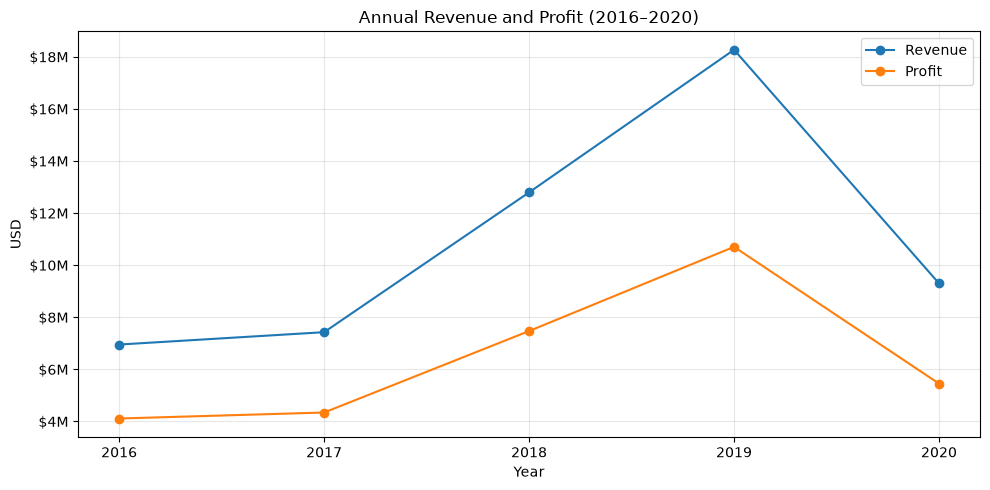

In [63]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

annual_financials = yearly_performance[
    yearly_performance["Year"] <= 2020
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    annual_financials["Year"],
    annual_financials["Revenue_USD"],
    marker="o",
    label="Revenue"
)

ax.plot(
    annual_financials["Year"],
    annual_financials["Profit_USD"],
    marker="o",
    label="Profit"
)

ax.set_title("Annual Revenue and Profit (2016–2020)")
ax.set_xlabel("Year")
ax.set_ylabel("USD")

ax.set_xticks(annual_financials["Year"])

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.0f}M")
)

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    "images/annual_revenue_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings

- Revenue increased from $6.95M in 2016 to a peak of $18.26M in 2019.
- Profit followed a similar trend, increasing from $4.11M in 2016 to $10.70M in 2019.
- Order volume grew significantly, from 2,865 orders in 2016 to 9,083 orders in 2019.
- The strongest annual growth occurred in 2018, when revenue increased by 72.32% and orders increased by 81.86%.
- Revenue, profit, and order volume declined by approximately 49% in 2020 compared with 2019.
- Profit margin remained highly stable throughout the period, staying between approximately 58% and 59%.
- Average Order Value declined from $2,424.71 in 2016 to $2,005.31 in 2020, indicating that order growth was driven more by transaction volume than by higher spending per order.
- 2021 contains data only through February 20 and is therefore excluded from direct full-year performance comparisons.

### Business Question 2: Which product categories and subcategories generate the most revenue and profit?

This analysis evaluates product performance across categories and subcategories
using revenue, profit, units sold, order volume, and profit margin.

The objective is to identify which parts of the product portfolio contribute
the most to overall financial performance.

In [64]:
category_performance = (
    sales_analysis
    .groupby("Category")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

category_performance["Profit_Margin_%"] = (
    category_performance["Profit_USD"]
    / category_performance["Revenue_USD"]
    * 100
)

category_performance["Revenue_Share_%"] = (
    category_performance["Revenue_USD"]
    / category_performance["Revenue_USD"].sum()
    * 100
)

category_performance = category_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

category_performance

,Category,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%,Revenue_Share_%
3,Computers,19301595.46,11277447.90,10990,44151,58.427543,34.618293
5,Home Appliances,10795478.59,6296338.85,5195,18401,58.323851,19.362184
1,Cameras and camcorders,6520168.02,3919800.99,4995,17609,60.118098,11.694219
2,Cell phones,6183791.22,3498626.54,8442,31477,56.577372,11.090912
7,TV and Video,5928982.69,3536694.39,3325,11236,59.650948,10.633901
0,Audio,3169627.74,1827851.77,6625,23490,57.667711,5.684872
6,"Music, Movies and Audio Books",3131006.44,1909259.17,7784,28802,60.979088,5.615603
4,Games and Toys,724829.43,396668.77,6128,22591,54.725809,1.300015


In [65]:
category_summary = category_performance.copy()

category_summary["Revenue_USD"] = category_summary["Revenue_USD"].round(2)
category_summary["Profit_USD"] = category_summary["Profit_USD"].round(2)
category_summary["Profit_Margin_%"] = (
    category_summary["Profit_Margin_%"].round(2)
)
category_summary["Revenue_Share_%"] = (
    category_summary["Revenue_Share_%"].round(2)
)

category_summary

,Category,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%,Revenue_Share_%
3,Computers,19301595.46,11277447.90,10990,44151,58.43,34.62
5,Home Appliances,10795478.59,6296338.85,5195,18401,58.32,19.36
1,Cameras and camcorders,6520168.02,3919800.99,4995,17609,60.12,11.69
2,Cell phones,6183791.22,3498626.54,8442,31477,56.58,11.09
7,TV and Video,5928982.69,3536694.39,3325,11236,59.65,10.63
0,Audio,3169627.74,1827851.77,6625,23490,57.67,5.68
6,"Music, Movies and Audio Books",3131006.44,1909259.17,7784,28802,60.98,5.62
4,Games and Toys,724829.43,396668.77,6128,22591,54.73,1.30


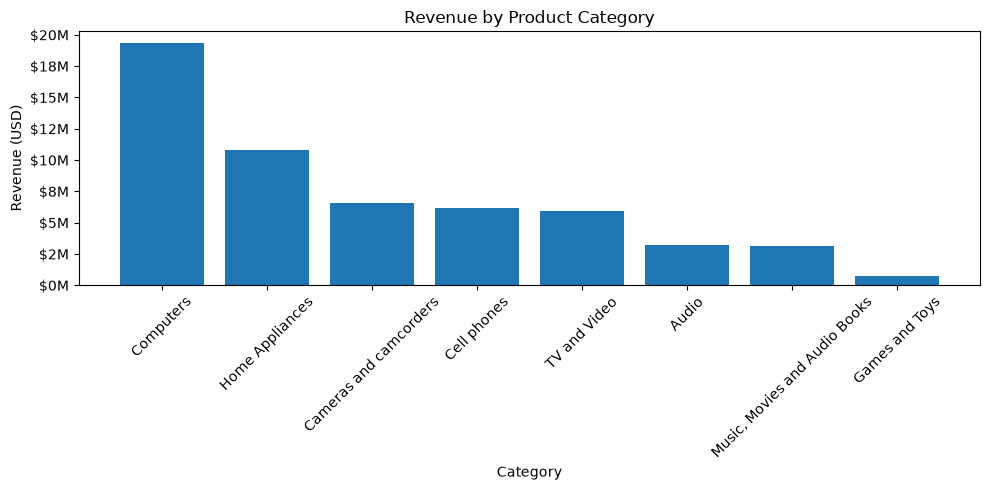

In [66]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    category_performance["Category"],
    category_performance["Revenue_USD"]
)

ax.set_title("Revenue by Product Category")
ax.set_xlabel("Category")
ax.set_ylabel("Revenue (USD)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.0f}M")
)

ax.tick_params(axis="x", rotation=45)

fig.tight_layout()

fig.savefig(
    "images/revenue_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
subcategory_performance = (
    sales_analysis
    .groupby(["Category", "Subcategory"])
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

subcategory_performance["Profit_Margin_%"] = (
    subcategory_performance["Profit_USD"]
    / subcategory_performance["Revenue_USD"]
    * 100
)

subcategory_performance = subcategory_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

subcategory_performance.head(10)

,Category,Subcategory,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%
12,Computers,Desktops,9906356.50,5629155.33,5751,20626,56.823670
30,TV and Video,Televisions,4308719.19,2631908.38,1723,5625,61.083312
16,Computers,Projectors & Screens,3767522.00,2357342.37,1468,4757,62.570102
26,Home Appliances,Water Heaters,3547822.50,2039982.30,1430,4563,57.499559
3,Cameras and camcorders,Camcorders,3357990.00,2018119.70,1363,4482,60.099038
13,Computers,Laptops,3164777.20,1793677.71,1543,4947,56.676271
27,"Music, Movies and Audio Books",Movie DVD,3131006.44,1909259.17,7784,28802,60.979088
10,Cell phones,Touch Screen Phones,3083462.00,1738593.81,3173,10630,56.384473
9,Cell phones,Smart phones & PDAs,2805657.00,1590479.02,3130,10077,56.688292
24,Home Appliances,Refrigerators,2152664.41,1316366.73,704,2324,61.150578


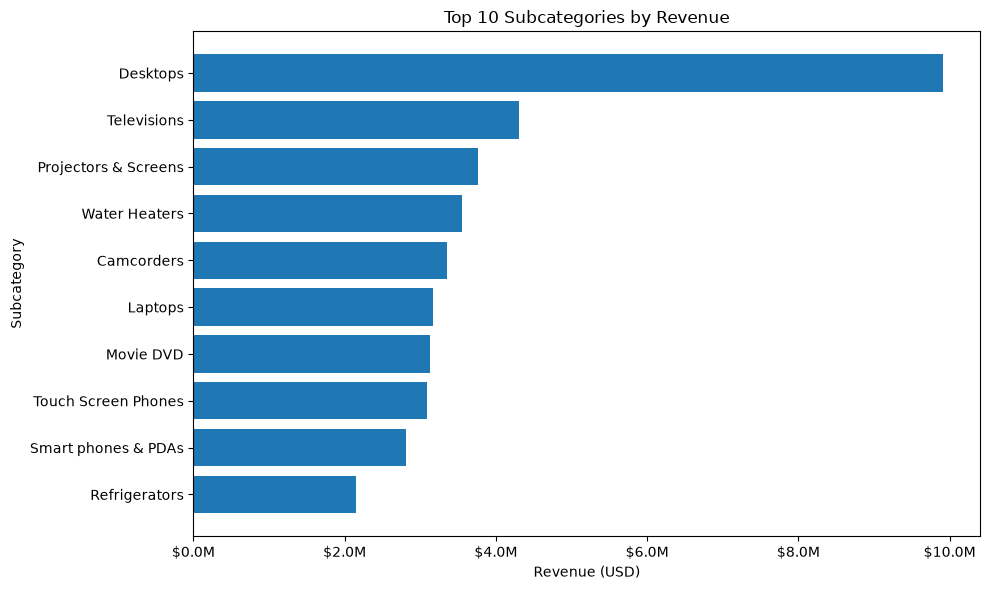

In [68]:
top_subcategories = subcategory_performance.head(10).sort_values(
    "Revenue_USD"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_subcategories["Subcategory"],
    top_subcategories["Revenue_USD"]
)

ax.set_title("Top 10 Subcategories by Revenue")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("Subcategory")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

fig.tight_layout()

fig.savefig(
    "images/top_subcategories_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings

- Computers was the highest-performing product category, generating $19.30M in revenue and $11.28M in profit, representing 34.62% of total revenue.
- Home Appliances ranked second with $10.80M in revenue and accounted for 19.36% of total revenue.
- Together, Computers and Home Appliances generated approximately 54% of total revenue.
- Music, Movies and Audio Books achieved the highest category profit margin at approximately 60.98%, despite contributing only 5.62% of total revenue.
- Games and Toys generated a relatively high number of orders and units sold but only $0.72M in revenue, indicating a comparatively low-value product mix.
- Desktops were the strongest-performing subcategory, generating $9.91M in revenue and $5.63M in profit.
- Televisions and Projectors & Screens ranked second and third by revenue.
- The top 10 subcategories generated approximately 70.35% of total revenue, showing that sales are concentrated in a relatively small portion of the product portfolio.

> Note: Category-level order counts are not additive because a single order may contain products from multiple categories.

### Business Question 3: Which brands and individual products are the strongest performers?

This analysis evaluates brand- and product-level performance using revenue,
profit, units sold, order volume, and profit margin.

The objective is to identify the brands and products that contribute the most
to financial performance and determine whether the strongest revenue
performers are also the strongest profit performers.

In [69]:
brand_performance = (
    sales_analysis
    .groupby("Brand")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

brand_performance["Profit_Margin_%"] = (
    brand_performance["Profit_USD"]
    / brand_performance["Revenue_USD"]
    * 100
)

brand_performance["Revenue_Share_%"] = (
    brand_performance["Revenue_USD"]
    / brand_performance["Revenue_USD"].sum()
    * 100
)

brand_performance = brand_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

brand_summary = brand_performance.copy()

for col in [
    "Revenue_USD",
    "Profit_USD",
    "Profit_Margin_%",
    "Revenue_Share_%"
]:
    brand_summary[col] = brand_summary[col].round(2)

brand_summary.head(10)

,Brand,Revenue_USD,Profit_USD,Orders,Units_Sold,Profit_Margin_%,Revenue_Share_%
1,Adventure Works,11849909.32,6937318.88,5681,20099,58.54,21.25
2,Contoso,10792325.32,6321209.14,12155,49827,58.57,19.36
10,Wide World Importers,9172800.41,5367028.30,7538,27413,58.51,16.45
3,Fabrikam,6807893.52,4061475.11,3330,11384,59.66,12.21
9,The Phone Company,5386820.00,3057762.90,5424,18764,56.76,9.66
6,Proseware,3212628.02,1935287.10,2840,9427,60.24,5.76
4,Litware,2659498.78,1553765.19,1616,5309,58.42,4.77
7,Southridge Video,2578595.93,1522876.84,6869,24814,59.06,4.62
0,A. Datum,1486207.80,883502.31,1782,5655,59.45,2.67
5,Northwind Traders,1126069.54,649413.31,2299,7610,57.67,2.02


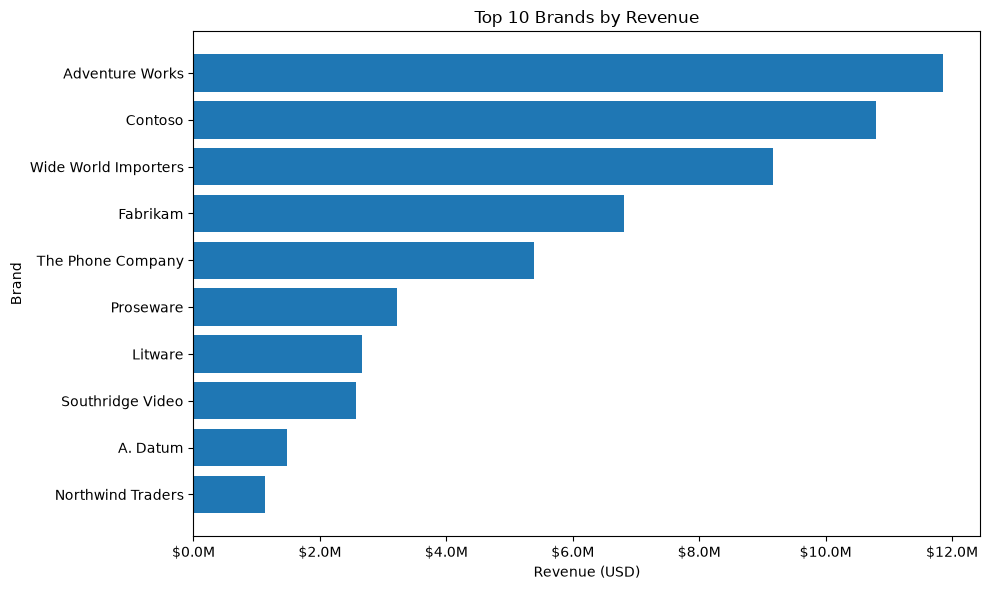

In [70]:
top_brands = brand_performance.head(10).sort_values(
    "Revenue_USD"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_brands["Brand"],
    top_brands["Revenue_USD"]
)

ax.set_title("Top 10 Brands by Revenue")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("Brand")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

fig.tight_layout()

fig.savefig(
    "images/top_brands_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
top_brands_profit = (
    brand_performance
    .sort_values("Profit_USD", ascending=False)
    .head(10)
)

top_brands_profit[
    [
        "Brand",
        "Revenue_USD",
        "Profit_USD",
        "Profit_Margin_%",
        "Orders",
        "Units_Sold"
    ]
]

,Brand,Revenue_USD,Profit_USD,Profit_Margin_%,Orders,Units_Sold
1,Adventure Works,11849909.32,6937318.88,58.543223,5681,20099
2,Contoso,10792325.32,6321209.14,58.571336,12155,49827
10,Wide World Importers,9172800.41,5367028.30,58.510248,7538,27413
3,Fabrikam,6807893.52,4061475.11,59.658323,3330,11384
9,The Phone Company,5386820.00,3057762.90,56.763785,5424,18764
6,Proseware,3212628.02,1935287.10,60.239999,2840,9427
4,Litware,2659498.78,1553765.19,58.423234,1616,5309
7,Southridge Video,2578595.93,1522876.84,59.058374,6869,24814
0,A. Datum,1486207.80,883502.31,59.446755,1782,5655
5,Northwind Traders,1126069.54,649413.31,57.670800,2299,7610


In [72]:
product_performance = (
    sales_analysis
    .groupby(
        [
            "ProductKey",
            "Product Name",
            "Brand",
            "Category",
            "Subcategory"
        ]
    )
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

product_performance["Profit_Margin_%"] = (
    product_performance["Profit_USD"]
    / product_performance["Revenue_USD"]
    * 100
)

product_performance = product_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

In [73]:
top_products_revenue = product_performance.head(10).copy()

top_products_revenue[
    [
        "Product Name",
        "Brand",
        "Category",
        "Revenue_USD",
        "Profit_USD",
        "Units_Sold",
        "Orders",
        "Profit_Margin_%"
    ]
]

,Product Name,Brand,Category,Revenue_USD,Profit_USD,Units_Sold,Orders,Profit_Margin_%
442,WWI Desktop PC2.33 X2330 Black,Wide World Importers,Computers,505450.00,337986.00,550,154,66.868335
414,Adventure Works Desktop PC2.33 XD233 Silver,Adventure Works,Computers,466089.00,311663.95,481,146,66.867905
426,Adventure Works Desktop PC2.33 XD233 Brown,Adventure Works,Computers,464151.00,310368.05,479,144,66.867905
420,Adventure Works Desktop PC2.33 XD233 Black,Adventure Works,Computers,447678.00,299352.90,462,151,66.867905
431,Adventure Works Desktop PC2.33 XD233 White,Adventure Works,Computers,437019.00,292225.45,451,141,66.867905
453,WWI Desktop PC2.33 X2330 White,Wide World Importers,Computers,424578.00,283908.24,462,131,66.868335
448,WWI Desktop PC2.33 X2330 Brown,Wide World Importers,Computers,422740.00,282679.20,460,151,66.868335
146,"Adventure Works 52"" LCD HDTV X590 White",Adventure Works,TV and Video,394398.64,263727.12,136,40,66.868162
145,"Adventure Works 52"" LCD HDTV X590 Black",Adventure Works,TV and Video,374098.71,250152.93,129,44,66.868162
436,WWI Desktop PC2.33 X2330 Silver,Wide World Importers,Computers,360248.00,240891.84,392,141,66.868335


In [74]:
top_products_profit = (
    product_performance
    .sort_values("Profit_USD", ascending=False)
    .head(10)
)

top_products_profit[
    [
        "Product Name",
        "Brand",
        "Category",
        "Revenue_USD",
        "Profit_USD",
        "Units_Sold",
        "Orders",
        "Profit_Margin_%"
    ]
]

,Product Name,Brand,Category,Revenue_USD,Profit_USD,Units_Sold,Orders,Profit_Margin_%
442,WWI Desktop PC2.33 X2330 Black,Wide World Importers,Computers,505450.00,337986.00,550,154,66.868335
414,Adventure Works Desktop PC2.33 XD233 Silver,Adventure Works,Computers,466089.00,311663.95,481,146,66.867905
426,Adventure Works Desktop PC2.33 XD233 Brown,Adventure Works,Computers,464151.00,310368.05,479,144,66.867905
420,Adventure Works Desktop PC2.33 XD233 Black,Adventure Works,Computers,447678.00,299352.90,462,151,66.867905
431,Adventure Works Desktop PC2.33 XD233 White,Adventure Works,Computers,437019.00,292225.45,451,141,66.867905
453,WWI Desktop PC2.33 X2330 White,Wide World Importers,Computers,424578.00,283908.24,462,131,66.868335
448,WWI Desktop PC2.33 X2330 Brown,Wide World Importers,Computers,422740.00,282679.20,460,151,66.868335
146,"Adventure Works 52"" LCD HDTV X590 White",Adventure Works,TV and Video,394398.64,263727.12,136,40,66.868162
145,"Adventure Works 52"" LCD HDTV X590 Black",Adventure Works,TV and Video,374098.71,250152.93,129,44,66.868162
436,WWI Desktop PC2.33 X2330 Silver,Wide World Importers,Computers,360248.00,240891.84,392,141,66.868335


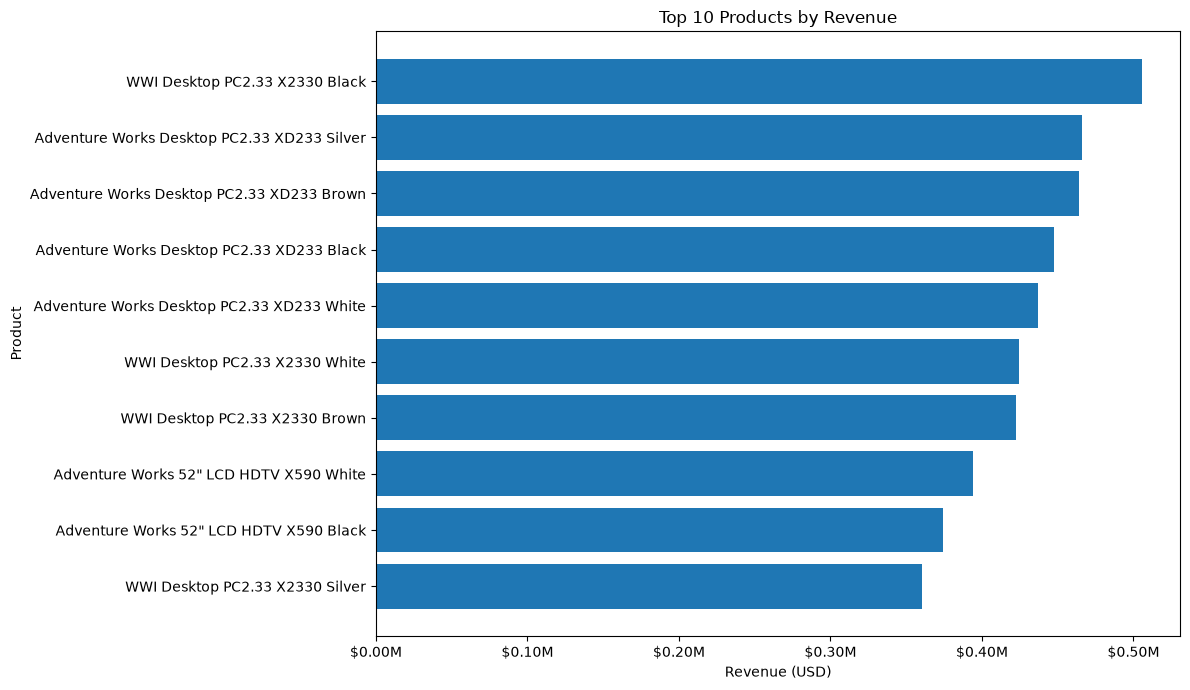

In [75]:
top_products_chart = (
    product_performance
    .head(10)
    .sort_values("Revenue_USD")
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_products_chart["Product Name"],
    top_products_chart["Revenue_USD"]
)

ax.set_title("Top 10 Products by Revenue")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("Product")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.2f}M")
)

fig.tight_layout()

fig.savefig(
    "images/top_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
top_products_units = (
    product_performance
    .sort_values("Units_Sold", ascending=False)
    .head(10)
)

top_products_units[
    [
        "Product Name",
        "Brand",
        "Revenue_USD",
        "Profit_USD",
        "Units_Sold",
        "Orders"
    ]
]

,Product Name,Brand,Revenue_USD,Profit_USD,Units_Sold,Orders
442,WWI Desktop PC2.33 X2330 Black,Wide World Importers,505450.00,337986.00,550,154
456,WWI Desktop PC1.80 E1800 White,Wide World Importers,123686.20,60627.22,538,158
422,Adventure Works Desktop PC1.60 ED160 Black,Adventure Works,140643.95,68938.72,521,154
432,Adventure Works Desktop PC2.30 MD230 White,Adventure Works,312079.00,168564.34,521,157
423,Adventure Works Desktop PC1.80 ED180 Black,Adventure Works,191880.00,94052.40,520,146
421,Adventure Works Desktop PC2.30 MD230 Black,Adventure Works,307886.00,166299.56,514,160
444,WWI Desktop PC1.60 E1600 Black,Wide World Importers,111954.55,54875.29,509,158
438,WWI Desktop PC1.60 E1600 Silver,Wide World Importers,111514.65,54659.67,507,154
446,WWI Desktop PC1.80 E1801 Black,Wide World Importers,136299.50,66811.50,505,156
433,Adventure Works Desktop PC1.60 ED160 White,Adventure Works,136324.75,66821.60,505,146


#### Findings

- Adventure Works was the highest-performing brand, generating $11.85M in revenue and $6.94M in profit.
- Contoso ranked second in revenue at $10.79M but recorded the highest sales activity, with 12,155 orders and 49,827 units sold.
- Wide World Importers ranked third, generating $9.17M in revenue and $5.37M in profit.
- The top three brands accounted for approximately 57.06% of total revenue, while the top five accounted for approximately 78.93%, indicating a relatively concentrated brand portfolio.
- Profit margins were broadly similar across the leading brands. Proseware recorded the highest margin among the top brands at approximately 60.24%, while The Phone Company recorded one of the lowest at approximately 56.76%.
- The highest-revenue products were heavily concentrated in the Computers category, particularly desktop computers from Adventure Works and Wide World Importers.
- WWI Desktop PC2.33 X2330 Black was the strongest individual product, generating $505.45K in revenue and $337.99K in profit.
- The same product also recorded the highest unit sales among individual products, with 550 units sold.
- Revenue and profit rankings were broadly aligned because product-level profit margins were relatively consistent among the leading products.

> Note: Brand-level order counts are not additive because a single customer order may contain products from multiple brands.

### Business Question 4: Which countries and markets generate the highest revenue and profit?

This analysis evaluates geographic performance using the customer's country as
the market dimension.

Revenue, profit, order volume, units sold, average order value, and profit
margin are compared across countries to identify the strongest markets.

Customer Country is used instead of Store Country because online transactions
are associated with the Online store rather than a physical country.

In [77]:
order_customer_check = (
    sales_analysis
    .groupby("Order Number")["CustomerKey"]
    .nunique()
)

print(
    "Orders linked to more than one customer:",
    (order_customer_check > 1).sum()
)

Orders linked to more than one customer: 0


In [78]:
country_performance = (
    sales_analysis
    .groupby("Customer Country")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

country_performance["Profit_Margin_%"] = (
    country_performance["Profit_USD"]
    / country_performance["Revenue_USD"]
    * 100
)

country_performance["Average_Order_Value_USD"] = (
    country_performance["Revenue_USD"]
    / country_performance["Orders"]
)

country_performance["Revenue_Share_%"] = (
    country_performance["Revenue_USD"]
    / country_performance["Revenue_USD"].sum()
    * 100
)

country_performance = country_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

In [79]:
country_summary = country_performance.copy()

for col in [
    "Revenue_USD",
    "Profit_USD",
    "Profit_Margin_%",
    "Average_Order_Value_USD",
    "Revenue_Share_%"
]:
    country_summary[col] = country_summary[col].round(2)

country_summary

,Customer Country,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Average_Order_Value_USD,Revenue_Share_%
7,United States,29871631.17,17490924.05,14221,106407,5706,58.55,2100.53,53.58
6,United Kingdom,7084088.12,4133800.81,3421,25298,1570,58.35,2070.77,12.71
3,Germany,5414149.80,3185916.46,2440,18943,1150,58.84,2218.91,9.71
1,Canada,4724334.63,2755738.22,2281,16793,1179,58.33,2071.17,8.47
0,Australia,2708137.61,1597300.18,1182,9209,780,58.98,2291.15,4.86
4,Italy,2475645.77,1450851.09,1101,8470,530,58.60,2248.54,4.44
5,Netherlands,1962154.27,1154644.08,976,7252,534,58.85,2010.40,3.52
2,France,1515338.22,893513.49,704,5385,438,58.96,2152.47,2.72


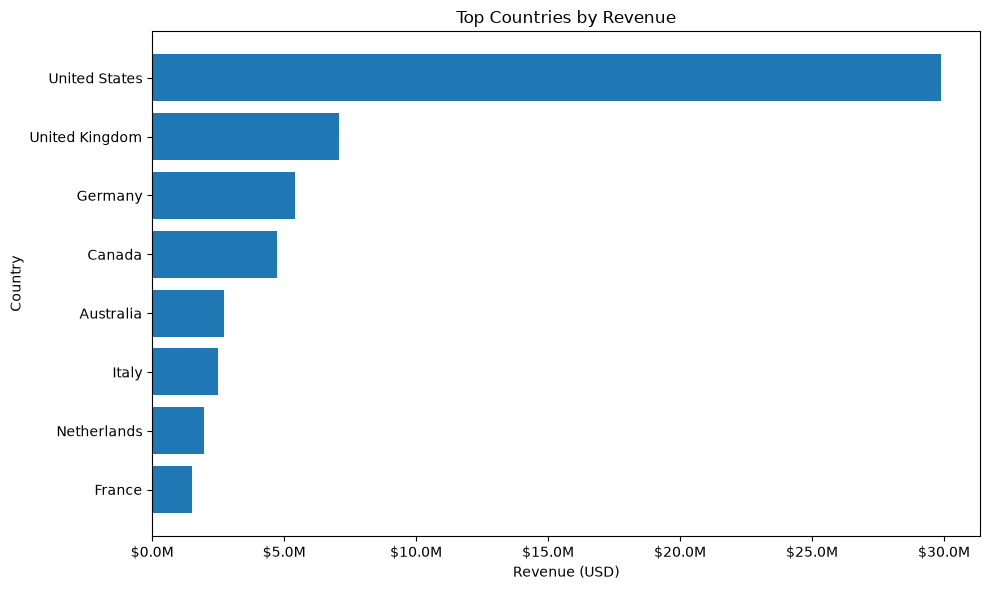

In [80]:
top_countries = (
    country_performance
    .head(10)
    .sort_values("Revenue_USD")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_countries["Customer Country"],
    top_countries["Revenue_USD"]
)

ax.set_title("Top Countries by Revenue")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("Country")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

fig.tight_layout()

fig.savefig(
    "images/top_countries_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
top_countries_profit = (
    country_performance
    .sort_values("Profit_USD", ascending=False)
    .head(10)
)

top_countries_profit[
    [
        "Customer Country",
        "Revenue_USD",
        "Profit_USD",
        "Profit_Margin_%",
        "Orders",
        "Customers",
        "Average_Order_Value_USD"
    ]
]

,Customer Country,Revenue_USD,Profit_USD,Profit_Margin_%,Orders,Customers,Average_Order_Value_USD
7,United States,29871631.17,17490924.05,58.553629,14221,5706,2100.529581
6,United Kingdom,7084088.12,4133800.81,58.353323,3421,1570,2070.765308
3,Germany,5414149.80,3185916.46,58.844261,2440,1150,2218.913852
1,Canada,4724334.63,2755738.22,58.330716,2281,1179,2071.168185
0,Australia,2708137.61,1597300.18,58.981500,1182,780,2291.148570
4,Italy,2475645.77,1450851.09,58.604955,1101,530,2248.542934
5,Netherlands,1962154.27,1154644.08,58.845734,976,534,2010.403965
2,France,1515338.22,893513.49,58.964624,704,438,2152.469062


In [82]:
continent_performance = (
    sales_analysis
    .groupby("Continent")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

continent_performance["Profit_Margin_%"] = (
    continent_performance["Profit_USD"]
    / continent_performance["Revenue_USD"]
    * 100
)

continent_performance["Revenue_Share_%"] = (
    continent_performance["Revenue_USD"]
    / continent_performance["Revenue_USD"].sum()
    * 100
)

continent_performance = continent_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

continent_performance.round(2)

,Continent,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Revenue_Share_%
2,North America,34595965.80,20246662.27,16502,123200,6885,58.52,62.05
1,Europe,18451376.18,10818725.93,8642,65348,4222,58.63,33.09
0,Australia,2708137.61,1597300.18,1182,9209,780,58.98,4.86


In [83]:
country_performance["Revenue_Per_Customer_USD"] = (
    country_performance["Revenue_USD"]
    / country_performance["Customers"]
)

country_performance[
    [
        "Customer Country",
        "Customers",
        "Revenue_USD",
        "Revenue_Per_Customer_USD",
        "Average_Order_Value_USD"
    ]
].sort_values(
    "Revenue_Per_Customer_USD",
    ascending=False
).head(10)

,Customer Country,Customers,Revenue_USD,Revenue_Per_Customer_USD,Average_Order_Value_USD
7,United States,5706,29871631.17,5235.126388,2100.529581
3,Germany,1150,5414149.80,4707.956348,2218.913852
4,Italy,530,2475645.77,4671.029755,2248.542934
6,United Kingdom,1570,7084088.12,4512.158038,2070.765308
1,Canada,1179,4724334.63,4007.069237,2071.168185
5,Netherlands,534,1962154.27,3674.446199,2010.403965
0,Australia,780,2708137.61,3471.971295,2291.148570
2,France,438,1515338.22,3459.676301,2152.469062


### Business Question 5: Which physical stores perform best and worst, and is store size associated with performance?

This analysis evaluates physical-store performance using revenue, profit,
orders, units sold, customers, average order value, and store size.

The online store (StoreKey = 0) is excluded because it does not represent a
physical location and has no square-meter measurement.

Store efficiency is also evaluated using revenue and profit per square meter.

In [84]:
physical_sales = sales_analysis[
    sales_analysis["StoreKey"] != 0
].copy()

order_store_check = (
    physical_sales
    .groupby("Order Number")["StoreKey"]
    .nunique()
)

print(
    "Orders linked to more than one physical store:",
    (order_store_check > 1).sum()
)

Orders linked to more than one physical store: 0


In [85]:
physical_stores = stores_clean[
    stores_clean["StoreKey"] != 0
].copy()

In [86]:
store_sales_agg = (
    physical_sales
    .groupby("StoreKey")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

In [87]:
store_performance = physical_stores.merge(
    store_sales_agg,
    on="StoreKey",
    how="left",
    validate="one_to_one"
)

In [88]:
activity_columns = [
    "Revenue_USD",
    "Profit_USD",
    "Orders",
    "Units_Sold",
    "Customers"
]

store_performance[activity_columns] = (
    store_performance[activity_columns]
    .fillna(0)
)

In [89]:
store_performance["Profit_Margin_%"] = np.where(
    store_performance["Revenue_USD"] > 0,
    store_performance["Profit_USD"]
    / store_performance["Revenue_USD"]
    * 100,
    np.nan
)

store_performance["Average_Order_Value_USD"] = np.where(
    store_performance["Orders"] > 0,
    store_performance["Revenue_USD"]
    / store_performance["Orders"],
    np.nan
)

store_performance["Revenue_Per_Sq_Meter_USD"] = (
    store_performance["Revenue_USD"]
    / store_performance["Square Meters"]
)

store_performance["Profit_Per_Sq_Meter_USD"] = (
    store_performance["Profit_USD"]
    / store_performance["Square Meters"]
)

In [90]:
no_sales_stores = store_performance[
    store_performance["Orders"] == 0
]

print("Physical stores:", len(store_performance))
print("Stores with sales:", (store_performance["Orders"] > 0).sum())
print("Stores without sales:", len(no_sales_stores))

no_sales_stores[
    [
        "StoreKey",
        "Country",
        "State",
        "Square Meters",
        "Open Date"
    ]
]

Physical stores: 66
Stores with sales: 57
Stores without sales: 9


,StoreKey,Country,State,Square Meters,Open Date
2,3,Australia,South Australia,2000.0,2012-01-07
6,7,Canada,New Brunswick,1105.0,2007-05-07
10,11,Canada,Yukon,1210.0,2009-06-03
24,25,Germany,Mecklenburg-Vorpommern,1610.0,2010-01-01
34,35,Netherlands,Zeeland,1225.0,2007-05-07
45,46,United States,Delaware,1015.0,2012-08-08
51,52,United States,Mississippi,2000.0,2009-06-03
57,58,United States,North Dakota,1330.0,2007-07-08
59,60,United States,Rhode Island,1260.0,2005-04-04


In [91]:
active_stores = store_performance[
    store_performance["Orders"] > 0
].copy()

top_stores = (
    active_stores
    .sort_values("Revenue_USD", ascending=False)
    .head(10)
)

top_stores[
    [
        "StoreKey",
        "Country",
        "State",
        "Revenue_USD",
        "Profit_USD",
        "Orders",
        "Units_Sold",
        "Customers",
        "Profit_Margin_%",
        "Average_Order_Value_USD"
    ]
]

,StoreKey,Country,State,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Average_Order_Value_USD
54,55,United States,Nevada,1417885.41,830551.75,622.0,4826.0,533.0,58.576789,2279.558537
49,50,United States,Kansas,1394738.06,819659.12,605.0,4773.0,508.0,58.767961,2305.352165
53,54,United States,Nebraska,1384396.24,810300.06,629.0,4686.0,559.0,58.530935,2200.947917
8,9,Canada,Northwest Territories,1336150.06,774757.55,658.0,4894.0,515.0,57.984322,2030.623191
56,57,United States,New Mexico,1325611.89,784095.76,605.0,4407.0,540.0,59.149723,2191.094033
44,45,United States,Connecticut,1318787.92,761271.82,617.0,4672.0,523.0,57.725113,2137.419643
60,61,United States,South Carolina,1305684.43,764997.20,624.0,4771.0,525.0,58.589747,2092.442997
58,59,United States,Oregon,1302272.44,754702.32,619.0,4674.0,515.0,57.952721,2103.832698
63,64,United States,Washington DC,1259350.98,745283.99,566.0,4289.0,502.0,59.180006,2225.001731
42,43,United States,Alaska,1250255.14,741093.00,558.0,4258.0,505.0,59.275341,2240.600609


In [92]:
bottom_stores = (
    active_stores
    .sort_values("Revenue_USD")
    .head(10)
)

bottom_stores[
    [
        "StoreKey",
        "Country",
        "State",
        "Revenue_USD",
        "Profit_USD",
        "Orders",
        "Units_Sold",
        "Customers",
        "Profit_Margin_%",
        "Average_Order_Value_USD"
    ]
]

,StoreKey,Country,State,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Average_Order_Value_USD
1,2,Australia,Northern Territory,15175.99,9512.61,4.0,61.0,4.0,62.681973,3793.997500
13,14,France,Franche-Comté,105714.05,63591.55,57.0,361.0,55.0,60.154303,1854.632456
12,13,France,Corse,150925.12,88957.65,80.0,592.0,76.0,58.941580,1886.564000
16,17,France,Martinique,159607.50,92449.65,79.0,626.0,73.0,57.923124,2020.348101
11,12,France,Basse-Normandie,183091.04,107084.53,90.0,748.0,85.0,58.487040,2034.344889
27,28,Italy,Caltanissetta,187109.49,108108.47,82.0,660.0,73.0,57.778186,2281.823049
15,16,France,Limousin,199009.69,119915.80,91.0,683.0,81.0,60.256262,2186.919670
14,15,France,La Réunion,205119.67,118097.69,93.0,715.0,89.0,57.575019,2205.587849
17,18,France,Mayotte,226078.88,135077.79,81.0,607.0,78.0,59.748080,2791.097284
0,1,Australia,Australian Capital Territory,243029.93,141355.64,111.0,871.0,105.0,58.163881,2189.458829


In [93]:
store_efficiency = (
    active_stores
    .sort_values(
        "Revenue_Per_Sq_Meter_USD",
        ascending=False
    )
)

store_efficiency[
    [
        "StoreKey",
        "Country",
        "State",
        "Square Meters",
        "Revenue_USD",
        "Revenue_Per_Sq_Meter_USD",
        "Profit_Per_Sq_Meter_USD"
    ]
].head(10)

,StoreKey,Country,State,Square Meters,Revenue_USD,Revenue_Per_Sq_Meter_USD,Profit_Per_Sq_Meter_USD
65,66,United States,Wyoming,840.0,1220964.38,1453.529024,860.940726
42,43,United States,Alaska,1190.0,1250255.14,1050.634571,622.767227
46,47,United States,Hawaii,1120.0,1130742.94,1009.591911,585.408661
55,56,United States,New Hampshire,1260.0,1207253.73,958.137881,561.612381
52,53,United States,Montana,1260.0,1193921.14,947.556460,552.985706
63,64,United States,Washington DC,1330.0,1259350.98,946.880436,560.363902
28,29,Italy,Enna,1000.0,913856.35,913.856350,538.542060
8,9,Canada,Northwest Territories,1500.0,1336150.06,890.766707,516.505033
50,51,United States,Maine,1295.0,1130592.31,873.044255,509.518371
9,10,Canada,Nunavut,1210.0,1043185.80,862.137025,501.073719


In [94]:
size_correlations = active_stores[
    [
        "Square Meters",
        "Revenue_USD",
        "Profit_USD",
        "Orders",
        "Units_Sold"
    ]
].corr()["Square Meters"]

size_correlations

Square Meters    1.000000
Revenue_USD      0.602223
Profit_USD       0.602119
Orders           0.592464
Units_Sold       0.602641
Name: Square Meters, dtype: float64

In [95]:
print(
    "Store Size vs Revenue:",
    round(
        active_stores["Square Meters"]
        .corr(active_stores["Revenue_USD"]),
        3
    )
)

print(
    "Store Size vs Profit:",
    round(
        active_stores["Square Meters"]
        .corr(active_stores["Profit_USD"]),
        3
    )
)

print(
    "Store Size vs Orders:",
    round(
        active_stores["Square Meters"]
        .corr(active_stores["Orders"]),
        3
    )
)

Store Size vs Revenue: 0.602
Store Size vs Profit: 0.602
Store Size vs Orders: 0.592


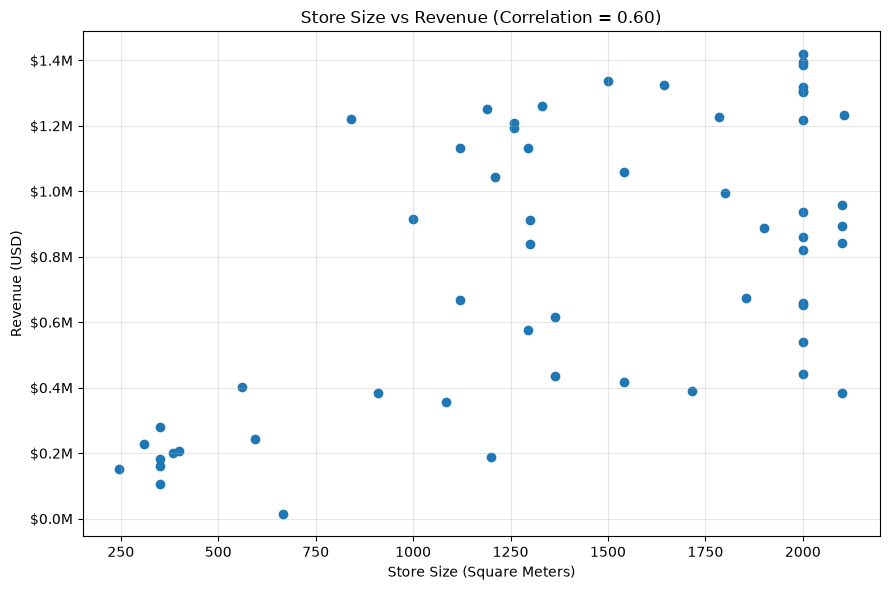

In [96]:
size_revenue_corr = (
    active_stores["Square Meters"]
    .corr(active_stores["Revenue_USD"])
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    active_stores["Square Meters"],
    active_stores["Revenue_USD"]
)

ax.set_title(
    f"Store Size vs Revenue (Correlation = {size_revenue_corr:.2f})"
)

ax.set_xlabel("Store Size (Square Meters)")
ax.set_ylabel("Revenue (USD)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    "images/store_size_vs_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

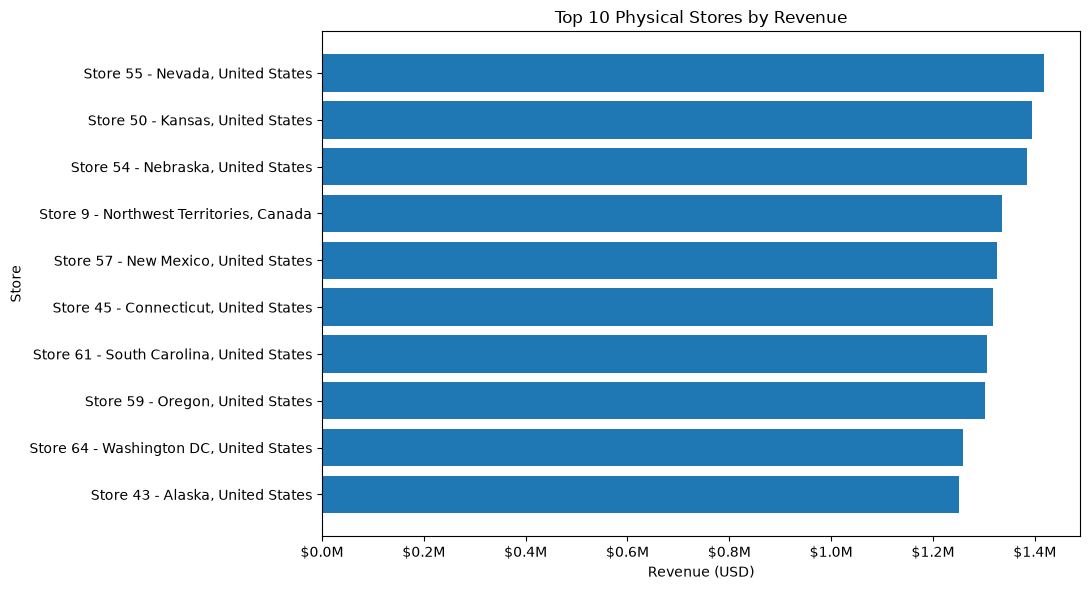

In [97]:
top_stores_chart = (
    top_stores
    .sort_values("Revenue_USD")
    .copy()
)

top_stores_chart["Store Label"] = (
    "Store "
    + top_stores_chart["StoreKey"].astype(str)
    + " - "
    + top_stores_chart["State"]
    + ", "
    + top_stores_chart["Country"]
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    top_stores_chart["Store Label"],
    top_stores_chart["Revenue_USD"]
)

ax.set_title("Top 10 Physical Stores by Revenue")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("Store")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

fig.tight_layout()

fig.savefig(
    "images/top_physical_stores_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings

- 66 physical stores are listed in the store dataset, of which 57 recorded sales during the analysis period and 9 recorded no sales.
- Stores with no recorded sales were separated from the active-store ranking rather than being classified as the worst-performing stores.
- Store 55 in Nevada was the highest-revenue physical store, generating approximately $1.42M in revenue and $0.83M in profit.
- Store 50 in Kansas ranked second with approximately $1.39M in revenue, followed by Store 54 in Nebraska with approximately $1.38M.
- Nine of the top ten physical stores by revenue were located in the United States, with Store 9 in Canada's Northwest Territories being the only non-U.S. store in the top ten.
- Among active stores, Store 2 in Australia's Northern Territory recorded the lowest revenue at approximately $15.2K, based on only four orders.
- Store size showed a moderate positive relationship with financial performance. The correlation between square meters and revenue was 0.602, while the correlation with profit was also 0.602.
- Store size and order volume had a correlation of 0.592, suggesting that larger stores generally handle more sales activity.
- Store 66 in Wyoming achieved the highest revenue efficiency at approximately $1,454 per square meter, despite not being the highest-revenue store overall.
- The results indicate that larger stores tend to perform better, but store size alone does not determine financial performance.

> Note: Stores with zero recorded transactions are reported separately and are not labeled as underperforming because the dataset does not provide enough information to determine why no sales were recorded.

### Business Question 6: How does online sales performance compare with physical stores?

This analysis compares online and physical-store sales across revenue, profit,
orders, units sold, customers, average order value, and profit margin.

The objective is to determine how each sales channel contributes to overall
business performance and whether customer purchasing behavior differs between
online and physical stores.

In [98]:
order_channel_check = (
    sales_analysis
    .groupby("Order Number")["Sales Channel"]
    .nunique()
)

print(
    "Orders linked to more than one sales channel:",
    (order_channel_check > 1).sum()
)

Orders linked to more than one sales channel: 0


In [99]:
channel_performance = (
    sales_analysis
    .groupby("Sales Channel")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

In [100]:
channel_performance["Profit_Margin_%"] = (
    channel_performance["Profit_USD"]
    / channel_performance["Revenue_USD"]
    * 100
)

channel_performance["Average_Order_Value_USD"] = (
    channel_performance["Revenue_USD"]
    / channel_performance["Orders"]
)

channel_performance["Units_Per_Order"] = (
    channel_performance["Units_Sold"]
    / channel_performance["Orders"]
)

channel_performance["Revenue_Share_%"] = (
    channel_performance["Revenue_USD"]
    / channel_performance["Revenue_USD"].sum()
    * 100
)

channel_performance["Order_Share_%"] = (
    channel_performance["Orders"]
    / channel_performance["Orders"].sum()
    * 100
)

In [101]:
channel_summary = channel_performance.copy()

for col in [
    "Revenue_USD",
    "Profit_USD",
    "Profit_Margin_%",
    "Average_Order_Value_USD",
    "Units_Per_Order",
    "Revenue_Share_%",
    "Order_Share_%"
]:
    channel_summary[col] = channel_summary[col].round(2)

channel_summary

,Sales Channel,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Average_Order_Value_USD,Units_Per_Order,Revenue_Share_%,Order_Share_%
0,Online,11404324.63,6672692.64,5580,41311,4547,58.51,2043.79,7.40,20.45,21.2
1,Physical Store,44351154.96,25989995.74,20746,156446,10657,58.60,2137.82,7.54,79.55,78.8


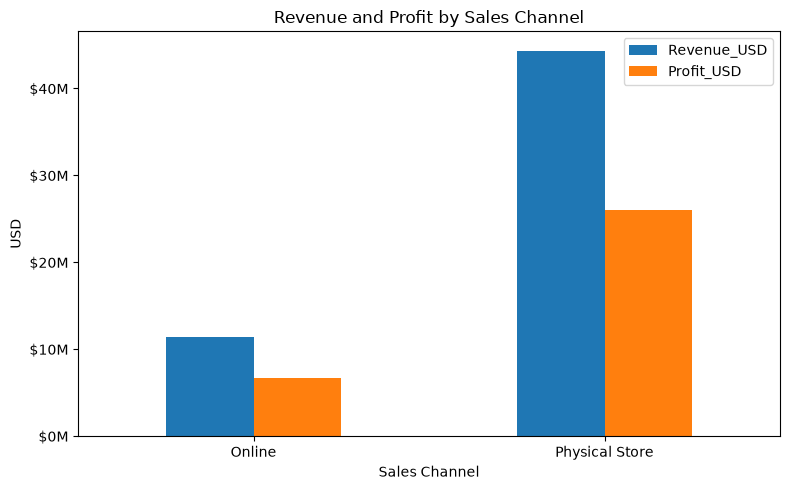

In [102]:
channel_chart = (
    channel_performance
    .set_index("Sales Channel")[
        ["Revenue_USD", "Profit_USD"]
    ]
)

fig, ax = plt.subplots(figsize=(8, 5))

channel_chart.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Revenue and Profit by Sales Channel")
ax.set_xlabel("Sales Channel")
ax.set_ylabel("USD")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.0f}M")
)

ax.tick_params(axis="x", rotation=0)

fig.tight_layout()

fig.savefig(
    "images/revenue_profit_by_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [103]:
channel_summary[
    [
        "Sales Channel",
        "Orders",
        "Customers",
        "Units_Sold",
        "Units_Per_Order",
        "Average_Order_Value_USD",
        "Revenue_Share_%",
        "Order_Share_%"
    ]
]

,Sales Channel,Orders,Customers,Units_Sold,Units_Per_Order,Average_Order_Value_USD,Revenue_Share_%,Order_Share_%
0,Online,5580,4547,41311,7.40,2043.79,20.45,21.2
1,Physical Store,20746,10657,156446,7.54,2137.82,79.55,78.8


In [104]:
online_delivery = sales_analysis[
    sales_analysis["Sales Channel"] == "Online"
]

print(
    "Average delivery days:",
    round(online_delivery["Delivery Days"].mean(), 2)
)

print(
    "Median delivery days:",
    round(online_delivery["Delivery Days"].median(), 2)
)

print(
    "Minimum delivery days:",
    int(online_delivery["Delivery Days"].min())
)

print(
    "Maximum delivery days:",
    int(online_delivery["Delivery Days"].max())
)

Average delivery days: 4.53
Median delivery days: 4.0
Minimum delivery days: 1
Maximum delivery days: 17


In [105]:
online_orders = (
    online_delivery[
        [
            "Order Number",
            "Order Date",
            "Delivery Date",
            "Delivery Days"
        ]
    ]
    .drop_duplicates(subset="Order Number")
)

In [106]:
print(
    "Online orders:",
    len(online_orders)
)

print(
    "Average delivery days:",
    round(online_orders["Delivery Days"].mean(), 2)
)

print(
    "Median delivery days:",
    round(online_orders["Delivery Days"].median(), 2)
)

print(
    "Minimum delivery days:",
    int(online_orders["Delivery Days"].min())
)

print(
    "Maximum delivery days:",
    int(online_orders["Delivery Days"].max())
)

Online orders: 5580
Average delivery days: 4.52
Median delivery days: 4.0
Minimum delivery days: 1
Maximum delivery days: 17


In [107]:
delivery_by_year = (
    online_orders
    .assign(
        Year=online_orders["Order Date"].dt.year
    )
    .groupby("Year")
    .agg(
        Online_Orders=("Order Number", "nunique"),
        Average_Delivery_Days=("Delivery Days", "mean"),
        Median_Delivery_Days=("Delivery Days", "median")
    )
    .reset_index()
)

delivery_by_year[
    "Average_Delivery_Days"
] = delivery_by_year[
    "Average_Delivery_Days"
].round(2)

delivery_by_year

,Year,Online_Orders,Average_Delivery_Days,Median_Delivery_Days
0,2016,476,7.17,7.0
1,2017,644,5.20,5.0
2,2018,1245,4.36,4.0
3,2019,2006,4.10,4.0
4,2020,1071,4.03,4.0
5,2021,138,3.78,4.0


In [108]:
channel_yearly = (
    sales_analysis
    .groupby(["Year", "Sales Channel"])
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Orders=("Order Number", "nunique")
    )
    .reset_index()
)

channel_yearly

,Year,Sales Channel,Revenue_USD,Orders
0,2016,Online,1169315.86,476
1,2016,Physical Store,5777477.70,2389
2,2017,Online,1388497.44,644
3,2017,Physical Store,6032924.83,2636
4,2018,Online,2582287.13,1245
5,2018,Physical Store,10206673.53,4720
6,2019,Online,3908495.70,2006
7,2019,Physical Store,14355886.78,7077
8,2020,Online,2069950.90,1071
9,2020,Physical Store,7224681.24,3564


In [109]:
channel_yearly["Revenue_Share_%"] = (
    channel_yearly["Revenue_USD"]
    / channel_yearly.groupby("Year")["Revenue_USD"].transform("sum")
    * 100
)

channel_yearly[
    "Revenue_Share_%"
] = channel_yearly[
    "Revenue_Share_%"
].round(2)

channel_yearly

,Year,Sales Channel,Revenue_USD,Orders,Revenue_Share_%
0,2016,Online,1169315.86,476,16.83
1,2016,Physical Store,5777477.70,2389,83.17
2,2017,Online,1388497.44,644,18.71
3,2017,Physical Store,6032924.83,2636,81.29
4,2018,Online,2582287.13,1245,20.19
5,2018,Physical Store,10206673.53,4720,79.81
6,2019,Online,3908495.70,2006,21.40
7,2019,Physical Store,14355886.78,7077,78.60
8,2020,Online,2069950.90,1071,22.27
9,2020,Physical Store,7224681.24,3564,77.73


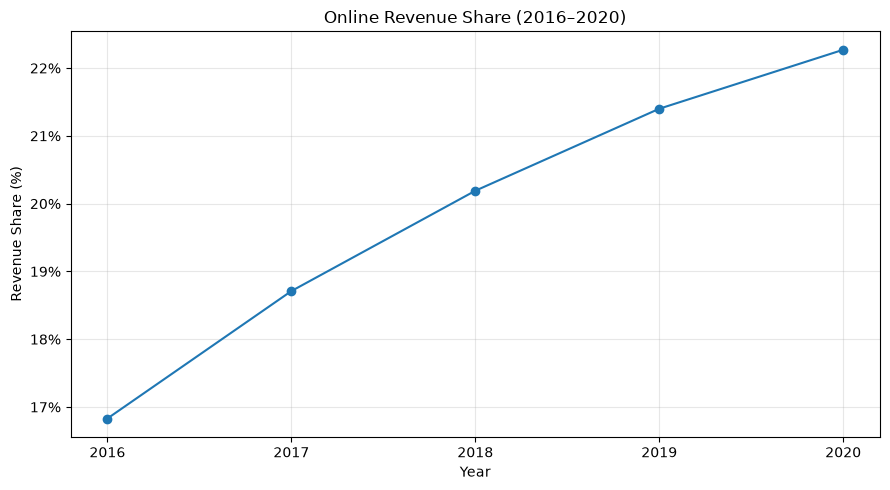

In [110]:
online_share = channel_yearly[
    (channel_yearly["Sales Channel"] == "Online")
    & (channel_yearly["Year"] <= 2020)
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    online_share["Year"],
    online_share["Revenue_Share_%"],
    marker="o"
)

ax.set_title("Online Revenue Share (2016–2020)")
ax.set_xlabel("Year")
ax.set_ylabel("Revenue Share (%)")

ax.set_xticks(online_share["Year"])

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:.0f}%")
)

ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    "images/online_revenue_share_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings

- Physical stores remained the dominant sales channel, generating $44.35M in revenue and $25.99M in profit, compared with $11.40M in revenue and $6.67M in profit from online sales.
- Physical stores accounted for 79.55% of total revenue and 78.80% of all orders, while online sales contributed 20.45% of revenue and 21.20% of orders.
- Profit margins were nearly identical across both channels: 58.60% for physical stores and 58.51% for online sales.
- Average Order Value was slightly higher in physical stores at $2,137.82 compared with $2,043.79 online.
- Units per order were also very similar, averaging 7.54 units in physical stores and 7.40 units online.
- Online revenue share increased steadily from 16.83% in 2016 to 22.27% in 2020, indicating gradual growth in the importance of the online channel.
- The online revenue share reached 27.50% in 2021; however, 2021 contains data only through February 20 and should not be treated as a full-year comparison.
- Average online delivery time improved substantially, declining from 7.17 days in 2016 to 4.03 days in 2020.
- Across all online orders, the average delivery time was 4.52 days, with a median of 4 days and a range of 1 to 17 days.

> Note: Delivery-time metrics are calculated at the order level rather than the sales-line level so that orders containing multiple products are not counted multiple times.

> Customer counts by sales channel are not additive because the same customer may have purchased through both online and physical channels.

### Business Question 7: Who are the highest-value customers, and how concentrated is revenue?

This analysis evaluates customer value using total revenue, profit, order
frequency, units purchased, and average order value.

It also examines repeat purchasing behavior and revenue concentration to
determine whether a small group of customers contributes a disproportionate
share of total sales.

In [111]:
customer_performance = (
    sales_analysis
    .groupby("CustomerKey")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Purchased=("Quantity", "sum"),
        First_Purchase=("Order Date", "min"),
        Last_Purchase=("Order Date", "max")
    )
    .reset_index()
)

In [112]:
customer_attributes = (
    customers_clean[
        [
            "CustomerKey",
            "Name",
            "Gender",
            "Country"
        ]
    ]
    .rename(
        columns={
            "Country": "Customer Country"
        }
    )
)

customer_performance = customer_performance.merge(
    customer_attributes,
    on="CustomerKey",
    how="left",
    validate="one_to_one"
)

In [113]:
customer_performance["Average_Order_Value_USD"] = (
    customer_performance["Revenue_USD"]
    / customer_performance["Orders"]
)

customer_performance["Profit_Margin_%"] = (
    customer_performance["Profit_USD"]
    / customer_performance["Revenue_USD"]
    * 100
)

customer_performance["Repeat_Customer"] = (
    customer_performance["Orders"] > 1
)

customer_performance = customer_performance.sort_values(
    "Revenue_USD",
    ascending=False
)

In [114]:
top_customers = customer_performance.head(10)

top_customers[
    [
        "CustomerKey",
        "Name",
        "Customer Country",
        "Revenue_USD",
        "Profit_USD",
        "Orders",
        "Units_Purchased",
        "Average_Order_Value_USD",
        "Profit_Margin_%"
    ]
]

,CustomerKey,Name,Customer Country,Revenue_USD,Profit_USD,Orders,Units_Purchased,Average_Order_Value_USD,Profit_Margin_%
9371,1702221,Matthew Flemming,United States,61871.70,39606.02,9,75,6874.633333,64.013143
10515,1884663,Karen Jones,United States,43517.80,28819.96,3,30,14505.933333,66.225682
11072,1969704,Zrina Topic,United States,42788.04,26008.23,7,60,6112.577143,60.783878
2743,535496,Stefanie Hartmann,Germany,41521.53,26957.37,3,35,13840.510000,64.923836
2840,551036,Stephan Rothstein,Germany,40556.54,26716.09,4,36,10139.135000,65.873691
3664,723572,Gaspare Trevisan,Italy,40225.01,23440.78,14,124,2873.215000,58.274143
1175,262871,Roy Le,Canada,38813.88,23986.19,3,32,12937.960000,61.797970
10795,1928466,Dennis Weissmuller,United States,38191.06,24054.60,4,40,9547.765000,62.984898
8116,1503831,Virgie Takacs,United States,37319.88,22881.47,3,29,12439.960000,61.311746
7275,1373561,Ollie Davis,United States,36817.28,22954.48,5,62,7363.456000,62.347028


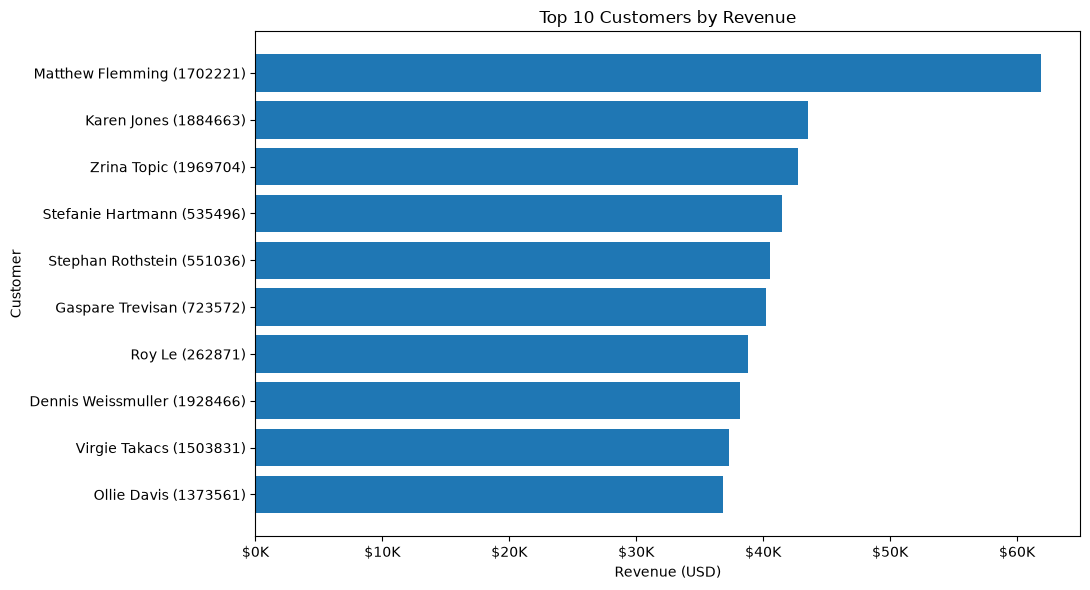

In [115]:
top_customers_chart = (
    top_customers
    .sort_values("Revenue_USD")
    .copy()
)

top_customers_chart["Customer Label"] = (
    top_customers_chart["Name"]
    + " ("
    + top_customers_chart["CustomerKey"].astype(str)
    + ")"
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    top_customers_chart["Customer Label"],
    top_customers_chart["Revenue_USD"]
)

ax.set_title("Top 10 Customers by Revenue")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("Customer")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000:.0f}K")
)

fig.tight_layout()

fig.savefig(
    "images/top_customers_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [116]:
total_customers = len(customer_performance)

repeat_customers = (
    customer_performance["Repeat_Customer"].sum()
)

one_time_customers = (
    total_customers - repeat_customers
)

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)

print(
    "Repeat customer rate:",
    f"{repeat_customers / total_customers * 100:.2f}%"
)

Total customers: 11887
Repeat customers: 7272
One-time customers: 4615
Repeat customer rate: 61.18%


In [117]:
customer_type_performance = (
    customer_performance
    .groupby("Repeat_Customer")
    .agg(
        Customers=("CustomerKey", "count"),
        Revenue_USD=("Revenue_USD", "sum"),
        Profit_USD=("Profit_USD", "sum"),
        Orders=("Orders", "sum")
    )
    .reset_index()
)

customer_type_performance["Customer Type"] = (
    customer_type_performance["Repeat_Customer"]
    .map({
        False: "One-time Customer",
        True: "Repeat Customer"
    })
)

customer_type_performance["Revenue_Share_%"] = (
    customer_type_performance["Revenue_USD"]
    / customer_type_performance["Revenue_USD"].sum()
    * 100
)

customer_type_performance[
    [
        "Customer Type",
        "Customers",
        "Orders",
        "Revenue_USD",
        "Profit_USD",
        "Revenue_Share_%"
    ]
]

,Customer Type,Customers,Orders,Revenue_USD,Profit_USD,Revenue_Share_%
0,One-time Customer,4615,4615,9819402.20,5751327.64,17.611546
1,Repeat Customer,7272,21711,45936077.39,26911360.74,82.388454


In [118]:
top_10_customer_share = (
    customer_performance
    .head(10)["Revenue_USD"]
    .sum()
    / customer_performance["Revenue_USD"].sum()
    * 100
)

print(
    "Revenue share from top 10 customers:",
    f"{top_10_customer_share:.2f}%"
)

Revenue share from top 10 customers: 0.76%


In [119]:
import math

top_10pct_count = math.ceil(
    len(customer_performance) * 0.10
)

top_10pct_revenue = (
    customer_performance
    .head(top_10pct_count)["Revenue_USD"]
    .sum()
)

top_10pct_share = (
    top_10pct_revenue
    / customer_performance["Revenue_USD"].sum()
    * 100
)

print("Top 10% customer count:", top_10pct_count)

print(
    "Revenue share from top 10% of customers:",
    f"{top_10pct_share:.2f}%"
)

Top 10% customer count: 1189
Revenue share from top 10% of customers: 35.98%


In [120]:
customer_order_distribution = (
    customer_performance["Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

customer_order_distribution.columns = [
    "Number_of_Orders",
    "Customers"
]

customer_order_distribution.head(15)

,Number_of_Orders,Customers
0,1,4615
1,2,3410
2,3,2003
3,4,1053
4,5,449
5,6,201
6,7,82
7,8,43
8,9,16
9,10,12


In [121]:
customer_performance[
    [
        "Revenue_USD",
        "Profit_USD",
        "Orders",
        "Units_Purchased",
        "Average_Order_Value_USD"
    ]
].describe()

,Revenue_USD,Profit_USD,Orders,Units_Purchased,Average_Order_Value_USD
count,11887.000000,11887.000000,11887.000000,11887.000000,11887.000000
mean,4690.458450,2747.765490,2.214688,16.636410,2122.457421
std,5197.622706,3191.879484,1.391487,13.599239,2251.639071
min,1.990000,0.980000,1.000000,1.000000,1.990000
25%,1138.915000,632.075000,1.000000,7.000000,713.959000
50%,2995.000000,1680.950000,2.000000,13.000000,1503.280000
75%,6425.065000,3689.840000,3.000000,23.000000,2723.533333
max,61871.700000,39606.020000,14.000000,124.000000,32056.890000


#### Findings

- The analysis identified 11,887 customers who made at least one purchase during the dataset period.
- Repeat customers represented 61.18% of customers and generated 82.39% of total revenue, highlighting the importance of repeat purchasing behavior.
- One-time customers accounted for 4,615 customers and contributed only 17.61% of total revenue.
- Matthew Flemming was the highest-value customer during the analysis period, generating $61.87K in revenue across 9 orders.
- Karen Jones ranked second with $43.52K in revenue from only 3 orders, resulting in a particularly high average order value of approximately $14.51K.
- Gaspare Trevisan recorded the highest purchase frequency among the top customers, with 14 orders and 124 units purchased.
- The top 10 customers generated only 0.76% of total revenue, indicating that overall sales are not heavily dependent on a handful of individual customers.
- The top 10% of customers generated 35.98% of total revenue, showing some customer-value concentration but not an extreme dependence on a small customer segment.
- Customer order frequency was generally low: the largest customer group consisted of customers with only one order, followed by customers with two and three orders.
- Median customer revenue was $2,995, compared with an average of $4,690, indicating that higher-spending customers pull the average upward.

> Note: Customer value is measured only during the dataset period and should not be interpreted as Customer Lifetime Value (CLV).

### Business Question 8: How does purchasing behavior differ across customer age groups and gender?

This analysis compares purchasing behavior across customer age groups and gender
using revenue, profit, orders, units sold, customer counts, average order value,
and revenue per customer.

Customer age is calculated at the time of purchase rather than using the
customer's current age.

In [122]:
age_bins = [0, 24, 34, 44, 54, 64, 200]

age_labels = [
    "Under 25",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

sales_analysis["Age Group"] = pd.cut(
    sales_analysis["Customer Age"],
    bins=age_bins,
    labels=age_labels
)

In [123]:
sales_analysis[
    ["Customer Age", "Age Group"]
].head(10)

,Customer Age,Age Group
0,44,35-44
1,20,Under 25
2,20,Under 25
3,53,45-54
4,53,45-54
5,53,45-54
6,36,35-44
7,36,35-44
8,20,Under 25
9,71,65+


In [124]:
sales_analysis["Age Group"].value_counts().sort_index()

Age Group
Under 25     8022
25-34        9377
35-44        9424
45-54        9386
55-64        9270
65+         17405
Name: count, dtype: int64

In [125]:
age_performance = (
    sales_analysis
    .groupby("Age Group", observed=True)
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

In [126]:
age_performance["Profit_Margin_%"] = (
    age_performance["Profit_USD"]
    / age_performance["Revenue_USD"]
    * 100
)

age_performance["Average_Order_Value_USD"] = (
    age_performance["Revenue_USD"]
    / age_performance["Orders"]
)

age_performance["Revenue_Per_Customer_USD"] = (
    age_performance["Revenue_USD"]
    / age_performance["Customers"]
)

age_performance["Units_Per_Order"] = (
    age_performance["Units_Sold"]
    / age_performance["Orders"]
)

In [127]:
age_summary = age_performance.copy()

for col in [
    "Revenue_USD",
    "Profit_USD",
    "Profit_Margin_%",
    "Average_Order_Value_USD",
    "Revenue_Per_Customer_USD",
    "Units_Per_Order"
]:
    age_summary[col] = age_summary[col].round(2)

age_summary

,Age Group,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Average_Order_Value_USD,Revenue_Per_Customer_USD,Units_Per_Order
0,Under 25,7058100.70,4124431.00,3291,25051,1574,58.44,2144.67,4484.18,7.61
1,25-34,8489991.81,4990553.73,3926,29773,2006,58.78,2162.50,4232.30,7.58
2,35-44,8425508.55,4940929.65,3937,29719,1972,58.64,2140.08,4272.57,7.55
3,45-54,8147490.87,4773721.37,3979,29099,1994,58.59,2047.62,4086.00,7.31
4,55-64,8202723.37,4793325.17,3905,29349,1981,58.44,2100.57,4140.70,7.52
5,65+,15431664.29,9039727.46,7288,54766,3376,58.58,2117.41,4570.99,7.51


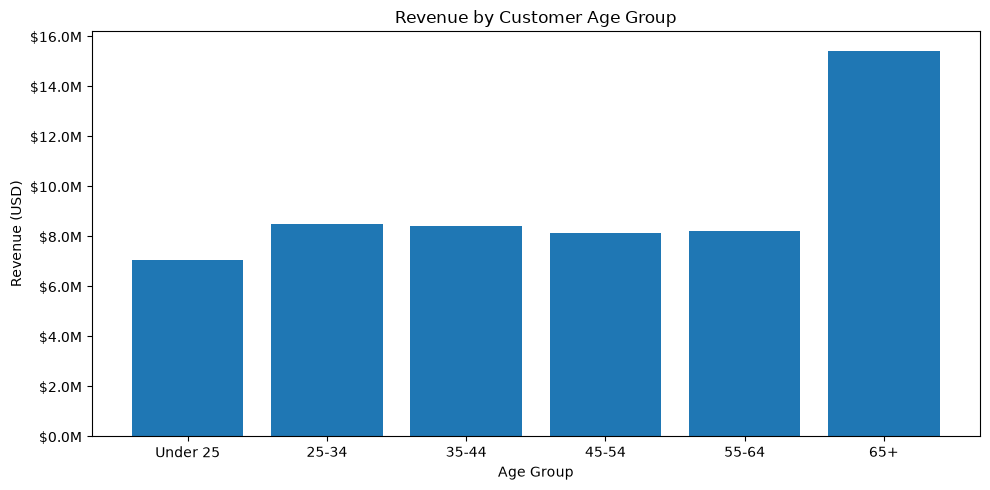

In [128]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    age_performance["Age Group"].astype(str),
    age_performance["Revenue_USD"]
)

ax.set_title("Revenue by Customer Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Revenue (USD)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

fig.tight_layout()

fig.savefig(
    "images/revenue_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [129]:
gender_performance = (
    sales_analysis
    .groupby("Gender")
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

In [130]:
gender_performance["Profit_Margin_%"] = (
    gender_performance["Profit_USD"]
    / gender_performance["Revenue_USD"]
    * 100
)

gender_performance["Average_Order_Value_USD"] = (
    gender_performance["Revenue_USD"]
    / gender_performance["Orders"]
)

gender_performance["Revenue_Per_Customer_USD"] = (
    gender_performance["Revenue_USD"]
    / gender_performance["Customers"]
)

gender_performance["Units_Per_Order"] = (
    gender_performance["Units_Sold"]
    / gender_performance["Orders"]
)

gender_performance.round(2)

,Gender,Revenue_USD,Profit_USD,Orders,Units_Sold,Customers,Profit_Margin_%,Average_Order_Value_USD,Revenue_Per_Customer_USD,Units_Per_Order
0,Female,27420624.99,16054988.39,12970,97694,5858,58.55,2114.16,4680.89,7.53
1,Male,28334854.60,16607699.99,13356,100063,6029,58.61,2121.51,4699.76,7.49


In [131]:
age_gender_performance = (
    sales_analysis
    .groupby(
        ["Age Group", "Gender"],
        observed=True
    )
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerKey", "nunique")
    )
    .reset_index()
)

age_gender_performance["Average_Order_Value_USD"] = (
    age_gender_performance["Revenue_USD"]
    / age_gender_performance["Orders"]
)

age_gender_performance["Revenue_Per_Customer_USD"] = (
    age_gender_performance["Revenue_USD"]
    / age_gender_performance["Customers"]
)

age_gender_performance.round(2)

,Age Group,Gender,Revenue_USD,Orders,Units_Sold,Customers,Average_Order_Value_USD,Revenue_Per_Customer_USD
0,Under 25,Female,3536664.43,1641,12431,777,2155.19,4551.69
1,Under 25,Male,3521436.27,1650,12620,797,2134.20,4418.36
2,25-34,Female,4311004.90,1954,14711,985,2206.25,4376.65
3,25-34,Male,4178986.91,1972,15062,1021,2119.16,4093.03
4,35-44,Female,4391115.30,2025,15322,1002,2168.45,4382.35
5,35-44,Male,4034393.25,1912,14397,970,2110.04,4159.17
6,45-54,Female,3881458.37,1920,14033,973,2021.59,3989.17
7,45-54,Male,4266032.50,2059,15066,1021,2071.90,4178.29
8,55-64,Female,3863937.51,1879,14223,976,2056.38,3958.95
9,55-64,Male,4338785.86,2026,15126,1005,2141.55,4317.20


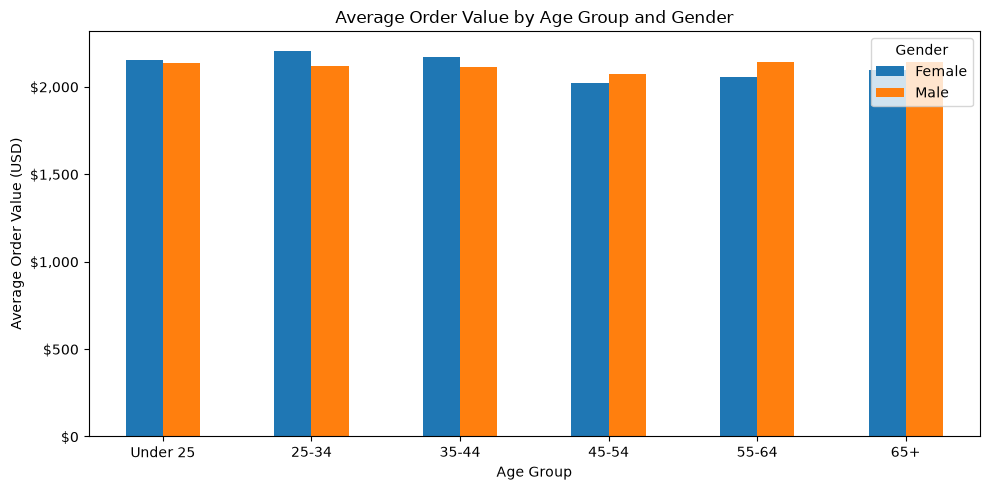

In [132]:
age_gender_aov = (
    age_gender_performance
    .pivot(
        index="Age Group",
        columns="Gender",
        values="Average_Order_Value_USD"
    )
)

fig, ax = plt.subplots(figsize=(10, 5))

age_gender_aov.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Average Order Value by Age Group and Gender")
ax.set_xlabel("Age Group")
ax.set_ylabel("Average Order Value (USD)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

ax.tick_params(axis="x", rotation=0)

fig.tight_layout()

fig.savefig(
    "images/aov_by_age_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Findings

- Customers aged 65+ generated the highest revenue at approximately $15.43M, representing about 27.68% of total revenue.
- The 65+ group also had the highest number of customers, with 3,376 unique customers, which explains a large part of its revenue lead.
- Revenue per customer was highest for the 65+ group at approximately $4,571, followed by customers under 25 at approximately $4,484.
- Average Order Value was relatively consistent across age groups, ranging from approximately $2,048 to $2,163.
- Customers aged 25–34 recorded the highest Average Order Value at approximately $2,163.
- Units per order were also highly consistent across age groups, ranging from approximately 7.31 to 7.61 units per order.
- These results suggest that age-group revenue differences are driven more by customer population and purchasing frequency than by major differences in basket size.

- Gender-based purchasing behavior was highly similar.
- Male customers generated 50.82% of total revenue, compared with 49.18% from female customers.
- Average Order Value was $2,121.51 for male customers and $2,114.16 for female customers, a difference of only about 0.35%.
- Revenue per customer was also nearly identical: approximately $4,700 for male customers and $4,681 for female customers.
- Profit margins and units per order were similarly close across genders.
- Overall, the dataset does not show a meaningful difference in purchasing behavior between male and female customers.

> Note: Customer age is calculated at the time of each purchase. A customer may therefore appear in more than one age group if they crossed an age-group boundary during the dataset period.

### Business Question 9: Are there seasonal patterns in sales and order activity?

This analysis examines monthly sales patterns to identify seasonality in revenue,
profit, order volume, and units sold.

Only complete years from 2016 through 2020 are used for the primary seasonal
analysis. The partial 2021 period is excluded to avoid biasing January and
February comparisons.

In [133]:
seasonality_data = sales_analysis[
    sales_analysis["Year"] <= 2020
].copy()

In [134]:
monthly_seasonality = (
    seasonality_data
    .groupby(["Month", "Month Name"])
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Profit_USD=("Profit USD", "sum"),
        Orders=("Order Number", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Month")
)

In [135]:
monthly_seasonality["Average_Annual_Revenue_USD"] = (
    monthly_seasonality["Revenue_USD"] / 5
)

monthly_seasonality["Average_Annual_Profit_USD"] = (
    monthly_seasonality["Profit_USD"] / 5
)

monthly_seasonality["Average_Annual_Orders"] = (
    monthly_seasonality["Orders"] / 5
)

monthly_seasonality["Average_Annual_Units"] = (
    monthly_seasonality["Units_Sold"] / 5
)

In [136]:
monthly_summary = monthly_seasonality[
    [
        "Month",
        "Month Name",
        "Average_Annual_Revenue_USD",
        "Average_Annual_Profit_USD",
        "Average_Annual_Orders",
        "Average_Annual_Units"
    ]
].copy()

for col in [
    "Average_Annual_Revenue_USD",
    "Average_Annual_Profit_USD",
    "Average_Annual_Orders",
    "Average_Annual_Units"
]:
    monthly_summary[col] = monthly_summary[col].round(2)

monthly_summary

,Month,Month Name,Average_Annual_Revenue_USD,Average_Annual_Profit_USD,Average_Annual_Orders,Average_Annual_Units
0,1,January,1249391.92,731227.50,588.4,4434.0
1,2,February,1463241.87,861830.08,658.8,4992.4
2,3,March,525104.57,309690.47,230.0,1775.2
3,4,April,121466.81,71725.86,53.0,400.2
4,5,May,951596.76,559189.05,440.6,3305.0
5,6,June,858607.31,500940.38,423.4,3107.6
6,7,July,770483.16,450525.51,371.2,2785.0
7,8,August,817033.86,479304.19,398.8,2950.2
8,9,September,872772.72,509406.16,414.0,3137.6
9,10,October,863005.49,502565.95,430.6,3251.6


In [137]:
print("Highest revenue month:")
display(
    monthly_summary.sort_values(
        "Average_Annual_Revenue_USD",
        ascending=False
    ).head(3)
)

print("Lowest revenue month:")
display(
    monthly_summary.sort_values(
        "Average_Annual_Revenue_USD"
    ).head(3)
)

Highest revenue month:


,Month,Month Name,Average_Annual_Revenue_USD,Average_Annual_Profit_USD,Average_Annual_Orders,Average_Annual_Units
11,12,December,1499321.77,872795.93,727.0,5422.8
1,2,February,1463241.87,861830.08,658.8,4992.4
0,1,January,1249391.92,731227.50,588.4,4434.0


Lowest revenue month:


,Month,Month Name,Average_Annual_Revenue_USD,Average_Annual_Profit_USD,Average_Annual_Orders,Average_Annual_Units
3,4,April,121466.81,71725.86,53.0,400.2
2,3,March,525104.57,309690.47,230.0,1775.2
6,7,July,770483.16,450525.51,371.2,2785.0


In [138]:
print("Highest order-volume month:")
display(
    monthly_summary.sort_values(
        "Average_Annual_Orders",
        ascending=False
    ).head(3)
)

Highest order-volume month:


,Month,Month Name,Average_Annual_Revenue_USD,Average_Annual_Profit_USD,Average_Annual_Orders,Average_Annual_Units
11,12,December,1499321.77,872795.93,727.0,5422.8
1,2,February,1463241.87,861830.08,658.8,4992.4
0,1,January,1249391.92,731227.50,588.4,4434.0


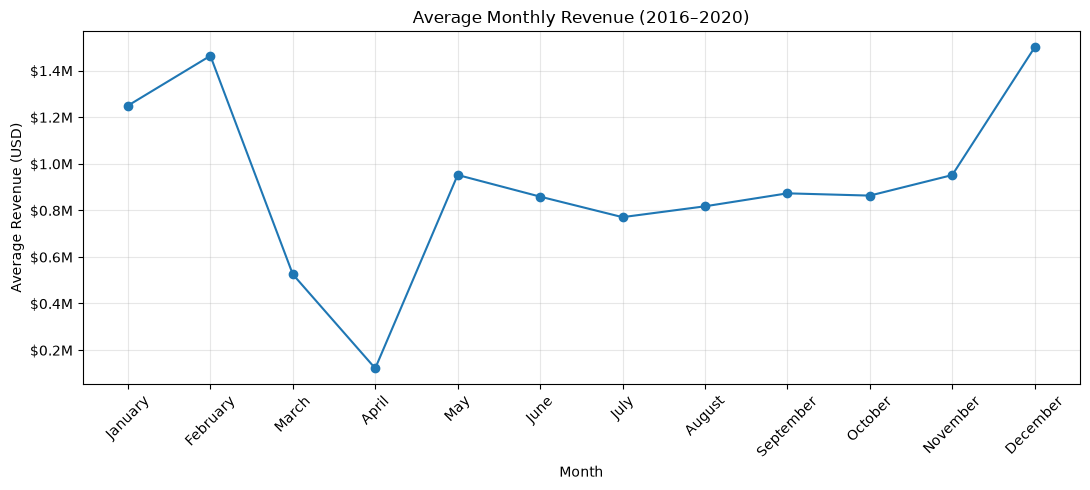

In [139]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    monthly_summary["Month Name"],
    monthly_summary["Average_Annual_Revenue_USD"],
    marker="o"
)

ax.set_title("Average Monthly Revenue (2016–2020)")
ax.set_xlabel("Month")
ax.set_ylabel("Average Revenue (USD)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    "images/monthly_revenue_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [140]:
monthly_by_year = (
    seasonality_data
    .groupby(["Year", "Month", "Month Name"])
    .agg(
        Revenue_USD=("Revenue USD", "sum"),
        Orders=("Order Number", "nunique")
    )
    .reset_index()
    .sort_values(["Year", "Month"])
)

In [141]:
monthly_revenue_pivot = (
    monthly_by_year
    .pivot(
        index="Month Name",
        columns="Year",
        values="Revenue_USD"
    )
    .reindex([
        "January",
        "February",
        "March",
        "April",
        "May",
        "June",
        "July",
        "August",
        "September",
        "October",
        "November",
        "December"
    ])
)

monthly_revenue_pivot

Year,2016,2017,2018,2019,2020
Month Name,,,,,
January,649918.78,670114.80,917075.35,1940899.57,2068951.12
February,891098.30,750526.19,1344342.70,2102862.57,2227379.57
March,338407.36,331248.59,434951.15,845925.09,674990.66
April,110591.63,58580.07,70627.54,149892.71,217642.10
May,595986.18,616258.96,1073265.56,1594446.47,878026.63
June,518585.28,631731.30,973975.33,1404861.40,763883.23
July,454959.83,511786.72,964149.46,1408714.62,512805.18
August,547512.69,593379.05,1026845.73,1500784.77,416647.08
September,567421.12,686375.10,1181765.14,1547870.73,380431.52


#### Findings

- Clear seasonal patterns were observed in both revenue and order activity across the complete years from 2016 through 2020.
- December was the strongest month on average, generating approximately $1.50M in annual average revenue and 727 orders.
- February ranked second with approximately $1.46M in average revenue, followed by January at approximately $1.25M.
- December alone represented approximately 13.70% of average annual revenue, while February contributed approximately 13.37%.
- April was consistently the weakest month, averaging only approximately $121K in revenue and 53 orders.
- March was the second-weakest month, averaging approximately $525K in revenue.
- Revenue typically recovered in May and remained relatively stable from May through November before reaching a strong peak in December.
- The strong December and early-year performance, along with the recurring weakness in March and April, appears across multiple years rather than being driven by a single year.
- 2020 showed a particularly sharp decline after February, but the broader March–April weakness is also visible in earlier years, indicating that the seasonal pattern is not unique to 2020.

> Note: The seasonal analysis uses only the complete years from 2016 through 2020. The partial 2021 period was excluded to avoid overstating January and February relative to the remaining months.

## 6. PostgreSQL Preparation

Following data cleaning, validation, and exploratory analysis, the cleaned
relational datasets are prepared for loading into PostgreSQL.

PostgreSQL is used as the relational database layer for the SQL analysis stage
of the project. The original multi-table structure is preserved so that the
analysis can demonstrate joins, aggregations, common table expressions (CTEs),
window functions, ranking, and other SQL techniques.

### PostgreSQL Database Design

The five cleaned datasets are modeled as relational tables in PostgreSQL:

- `customers` — customer attributes
- `products` — product and pricing information
- `stores` — physical and online store information
- `exchange_rates` — daily currency exchange rates
- `sales` — transaction line items

Database integrity is enforced using primary keys, foreign keys, composite
keys, check constraints, and indexes.

The complete database definition is available in:

`sql/schema.sql`

### Key Relationships

- `sales.customer_key` → `customers.customer_key`
- `sales.product_key` → `products.product_key`
- `sales.store_key` → `stores.store_key`
- `(sales.order_date, sales.currency_code)` →
  `(exchange_rates.rate_date, exchange_rates.currency)`

Each sales line is uniquely identified by the composite primary key:

`(order_number, line_item)`

### Exporting Cleaned Relational Tables

The cleaned relational tables are exported as processed CSV files for the
PostgreSQL loading stage.

Column names are converted to `snake_case` to match the PostgreSQL schema.

The processed files are stored locally under `data/processed/` and are excluded
from version control along with the rest of the `data/` directory.

In [142]:
from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

In [143]:
sales_db = sales_clean.rename(columns={
    "Order Number": "order_number",
    "Line Item": "line_item",
    "Order Date": "order_date",
    "Delivery Date": "delivery_date",
    "CustomerKey": "customer_key",
    "StoreKey": "store_key",
    "ProductKey": "product_key",
    "Quantity": "quantity",
    "Currency Code": "currency_code"
})

products_db = products_clean.rename(columns={
    "ProductKey": "product_key",
    "Product Name": "product_name",
    "Brand": "brand",
    "Color": "color",
    "Unit Cost USD": "unit_cost_usd",
    "Unit Price USD": "unit_price_usd",
    "SubcategoryKey": "subcategory_key",
    "Subcategory": "subcategory",
    "CategoryKey": "category_key",
    "Category": "category"
})

customers_db = customers_clean.rename(columns={
    "CustomerKey": "customer_key",
    "Gender": "gender",
    "Name": "name",
    "City": "city",
    "State Code": "state_code",
    "State": "state",
    "Zip Code": "zip_code",
    "Country": "country",
    "Continent": "continent",
    "Birthday": "birthday"
})

stores_db = stores_clean.rename(columns={
    "StoreKey": "store_key",
    "Country": "country",
    "State": "state",
    "Square Meters": "square_meters",
    "Open Date": "open_date"
})

exchange_rates_db = exchange_rates_clean.rename(columns={
    "Date": "rate_date",
    "Currency": "currency",
    "Exchange": "exchange_rate"
})

In [144]:
print("Sales:", sales_db.shape)
print("Products:", products_db.shape)
print("Customers:", customers_db.shape)
print("Stores:", stores_db.shape)
print("Exchange Rates:", exchange_rates_db.shape)

Sales: (62884, 9)
Products: (2517, 10)
Customers: (15266, 10)
Stores: (67, 5)
Exchange Rates: (11215, 3)


In [145]:
sales_db.to_csv(
    processed_dir / "sales_clean.csv",
    index=False,
    date_format="%Y-%m-%d"
)

products_db.to_csv(
    processed_dir / "products_clean.csv",
    index=False
)

customers_db.to_csv(
    processed_dir / "customers_clean.csv",
    index=False,
    date_format="%Y-%m-%d"
)

stores_db.to_csv(
    processed_dir / "stores_clean.csv",
    index=False,
    date_format="%Y-%m-%d"
)

exchange_rates_db.to_csv(
    processed_dir / "exchange_rates_clean.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Cleaned relational tables exported successfully.")

Cleaned relational tables exported successfully.


In [146]:
text_tables = {
    "customers": customers_db,
    "products": products_db,
    "stores": stores_db,
    "exchange_rates": exchange_rates_db,
    "sales": sales_db
}

for table_name, df in text_tables.items():
    print(f"\n{table_name.upper()}")

    for col in df.select_dtypes(include=["object", "string"]).columns:
        max_length = df[col].astype(str).str.len().max()
        longest_value = df.loc[
            df[col].astype(str).str.len().idxmax(),
            col
        ]

        print(
            f"{col:<20} max length = {max_length:<4} "
            f"example = {longest_value!r}"
        )


CUSTOMERS
gender               max length = 6    example = 'Female'
name                 max length = 27   example = 'Abdelghafour van Oudheusden'
city                 max length = 36   example = 'Neustadt an der Weinstraße Geinsheim'
state_code           max length = 28   example = 'Bath and North East Somerset'
state                max length = 28   example = 'Australian Capital Territory'
zip_code             max length = 8    example = 'SY24 5DZ'
country              max length = 14   example = 'United Kingdom'
continent            max length = 13   example = 'North America'

PRODUCTS
product_name         max length = 83   example = 'Proseware 23ppm Laser Printer with Wireless and Wired Network Interfaces M680 Black'
brand                max length = 20   example = 'Wide World Importers'
color                max length = 11   example = 'Silver Grey'
subcategory          max length = 32   example = 'Cameras & Camcorders Accessories'
category             max length = 29   example = 

### PostgreSQL Data Load

The cleaned relational tables were successfully loaded into PostgreSQL using
a dedicated Python loading script.

The loading process preserves the predefined PostgreSQL schema and database
constraints rather than replacing the tables through Pandas.

Data is loaded in dependency order to satisfy foreign key relationships:

1. `customers`
2. `products`
3. `stores`
4. `exchange_rates`
5. `sales`

Post-load validation was performed to confirm row counts and referential
integrity between the relational tables.

> Note: The source `State Code` field contains some values longer than
> conventional region abbreviations. The PostgreSQL `state_code` column was
> therefore expanded to `VARCHAR(100)` to preserve the original source values
> without truncation.

## 7. SQL Business Analysis

PostgreSQL was used to reproduce and extend the business analysis using the
cleaned relational database.

A reusable analytical view, `sales_enriched`, was created by joining the sales,
product, customer, store, and exchange-rate tables. The view also derives
revenue, cost, profit, sales channel, customer age at purchase, and delivery
duration.

The SQL analysis demonstrates relational joins, aggregations, Common Table
Expressions (CTEs), window functions, ranking, contribution analysis, and
other analytical SQL techniques.

The complete SQL analysis is available in:

`sql/electronics_analysis.sql`